# Combining G_004, G_005, B_036 and B_039 

In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import diffrax as dfx

# jax.config.update("jax_disable_jit",True)
jax.local_device_count()

import numpy as np
import matplotlib.pyplot as plt
import arviz as az
import xarray
import ICIW_Plots
import tqdm

plt.style.use("ICIWstyle")
plt.rcParams.update(
    {
        "figure.dpi": 600,
        "font.size": 7,
        # "axes.linewidth": 0.8,
        # "axes.spines.top": False,
        # "axes.spines.right": False,
        # "axes.grid": False,
        # "legend.frameon": False,
    }
)

In [2]:
%config InlineBackend.print_figure_kwargs = {'bbox_inches':None}


In [3]:
from HSA_B_039 import kl_divergence_between_models
from HSA_Mo_B_011 import (
    kinetics_model,
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    validate_against_holdout,
    sample_prior as sample_prior_11,
    TRUE_PARAMS,
)
from HSA_Mo_B_012 import sample_prior as sample_prior_12

In [4]:
ov = [
    {
        "ID": "B_039",
        "run_name": "agitated-health",
        "dir": Path("data/agitated-health"),
        "DOE": "paramEKLD DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
        "prior_sampling_function": sample_prior_11,
    },
    {
        "ID": "B_042",
        "run_name": "eternal-rock",
        "dir": Path("data/eternal-rock"),
        "DOE": "predEKLD DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
        "prior_sampling_function": sample_prior_11,
    },
    {
        "ID": "G_004",
        "run_name": "fumbling-sardine",
        "dir": Path("data/fumbling-sardine"),
        "DOE": "paramEKLD DOE iP",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
        "prior_sampling_function": sample_prior_12,
    },
    {
        "ID": "G_005",
        "run_name": "communal-butcher",
        "dir": Path("data/communal-butcher"),
        "DOE": "predEKLD DOE iP",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
        "prior_sampling_function": sample_prior_12,
    },

]

In [5]:
def load_files(ov_dict):
    sum_file = ov_dict["dir"] / f"experiment_summary_{ov_dict['run_name']}.json"
    trace_files = sorted(ov_dict["dir"].glob(f"trace_*.nc"))
    test_data = xarray.open_dataset(ov_dict["holdout_data"])
    idatas = []
    valdatas = []
    paramEKLDS = []
    paramEKLDS_to_prior = []
    for i, trace_file in enumerate(tqdm.tqdm(trace_files)):
        idata = az.from_netcdf(trace_file)
        if i == 0:
            print(ov_dict["prior_sampling_function"])
            idata.update(xarray.DataTree.from_dict({"prior": ov_dict["prior_sampling_function"](4000).prior}))
        else:
            idata.update(
                xarray.DataTree.from_dict({"prior": idatas[i - 1]["posterior"].dataset})
            )
        idatas.append(idata)
        valdata = validate_against_holdout(
            idata,
            test_data,
            num_samples=5000,
        )
        paramEKLD = kl_divergence_between_models(
            idata_new=idata,
            idata_old=idata,
            key_new="posterior",
            key_old="prior",
            var_names=[
                "k0",
                "Ea_k",
                "A_oh",
                "dH_oh",
                "A_h2",
                "dH_h2",
                "A_mix",
                "dH_mix",
                "sigma_r",
            ],
        ).sum()
        paramEKLD_to_prior = kl_divergence_between_models(
            idata_new=idata,
            idata_old=idatas[0],
            key_new="posterior",
            key_old="prior",
            var_names=[
                "k0",
                "Ea_k",
                "A_oh",
                "dH_oh",
                "A_h2",
                "dH_h2",
                "A_mix",
                "dH_mix",
                "sigma_r",
            ],
        ).sum()
        paramEKLDS.append(paramEKLD)
        paramEKLDS_to_prior.append(paramEKLD_to_prior)
        valdatas.append(valdata)
    ov_dict["idatas"] = idatas
    ov_dict["valdatas"] = valdatas
    ov_dict["paramEKLDS"] = paramEKLDS
    ov_dict["paramEKLDS_to_prior"] = paramEKLDS_to_prior
    with open(sum_file, "r") as f:
        exp_summary = json.load(f)
    ov_dict["proposals"] = np.array(exp_summary["trials"][-1]["observed"]["x"])
    ov_dict["r_obs"] = np.array(exp_summary["trials"][-1]["observed"]["y"])

In [6]:
for ov_dict in ov:
    load_files(ov_dict)
    print(ov_dict["r_obs"])

  0%|          | 0/32 [00:00<?, ?it/s]

<function sample_prior at 0x7a7eb71dad40>


100%|██████████| 32/32 [00:17<00:00,  1.82it/s]


[[7.54950349e-07]
 [1.76078247e-04]
 [7.83488867e-05]
 [2.62141293e-06]
 [9.66572225e-06]
 [2.32854203e-04]
 [1.05826416e-07]
 [1.02931401e-04]
 [3.88796224e-07]
 [1.41701472e-04]
 [7.86922328e-07]
 [3.08492672e-05]
 [3.32577329e-04]
 [3.63180163e-07]
 [4.65235316e-05]
 [3.30496334e-07]
 [7.09769495e-07]
 [1.32725283e-04]
 [2.48478551e-04]
 [2.55892694e-04]
 [3.82377242e-04]
 [3.86072752e-05]
 [2.34228821e-04]
 [3.39429789e-07]
 [1.03550792e-06]
 [1.97061837e-07]
 [1.77745333e-05]
 [1.57478453e-07]
 [1.71668819e-06]
 [7.75841613e-07]
 [2.54212704e-04]
 [2.96302478e-05]]


  0%|          | 0/32 [00:00<?, ?it/s]

...

[[4.66544807e-05]
 [3.00690353e-05]
 [1.25667654e-07]
 [2.41376154e-04]
 [2.64685659e-04]
 [4.03154758e-07]
 [8.43181454e-07]
 [2.28196404e-05]
 [1.36652248e-04]
 [3.57584213e-07]
 [2.79322005e-04]
 [3.33540447e-05]
 [1.29348666e-06]
 [1.84359379e-07]
 [2.16592389e-06]
 [8.02936825e-07]
 [4.62088174e-05]
 [1.95659795e-05]
 [5.74916044e-07]
 [1.39805445e-04]
 [2.92180448e-05]
 [2.23388211e-04]
 [1.10732663e-06]
 [2.62279500e-04]
 [1.71269022e-07]
 [5.24721181e-05]
 [1.05028505e-07]
 [4.23472841e-07]
 [2.98432453e-04]
 [1.78466435e-05]
 [7.18924355e-07]
 [4.33146852e-05]]


  0%|          | 0/32 [00:00<?, ?it/s]

<function sample_prior at 0x7a7eb71dbb00>


100%|██████████| 32/32 [00:16<00:00,  1.91it/s]

[[1.92604115e-04]
 [6.82538257e-07]
 [9.61110127e-05]
 [2.15417695e-05]
 [1.11558722e-06]
 [8.50876631e-07]
 [3.22822928e-07]
 [1.81968808e-05]
 [1.94787382e-04]
 [4.68486047e-04]
 [4.49879699e-05]
 [3.23675689e-04]
 [3.46739768e-07]
 [7.44968418e-07]
 [4.26985818e-04]
 [1.48655488e-07]
 [6.05440334e-07]
 [2.67684547e-04]
 [2.56042476e-05]
 [7.23675441e-07]
 [2.83547066e-04]
 [2.11772829e-04]
 [4.77172725e-05]
 [1.81970691e-07]
 [2.73920188e-04]
 [1.19002925e-06]
 [2.17921886e-04]
 [4.23472841e-07]
 [4.80533163e-05]
 [4.95536486e-04]
 [7.18924355e-07]
 [1.24168100e-05]]


manually overwrite the priors because sampling is 

In [7]:
# ov[2]["idatas"][0].prior = ov[3]["idatas"][0].prior

In [8]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[var_name].values
    pred = postdata.posterior_predictive[var_name].values
    res = true - pred
    rmse_vals = np.sqrt(np.mean(res**2, axis=2)).squeeze()
    return rmse_vals


def calculate_RMSEs(ov_dict):
    ov_dict["RMSEs"] = None
    for valdata in ov_dict["valdatas"]:
        rmse_da = bRMSE(valdata, "r_pred")
        if ov_dict["RMSEs"] is None:
            ov_dict["RMSEs"] = [rmse_da]
        else:
            ov_dict["RMSEs"].append(rmse_da)
    ov_dict["RMSEs"] = np.array(ov_dict["RMSEs"])

In [9]:
for ov_dict in ov:
    calculate_RMSEs(ov_dict)

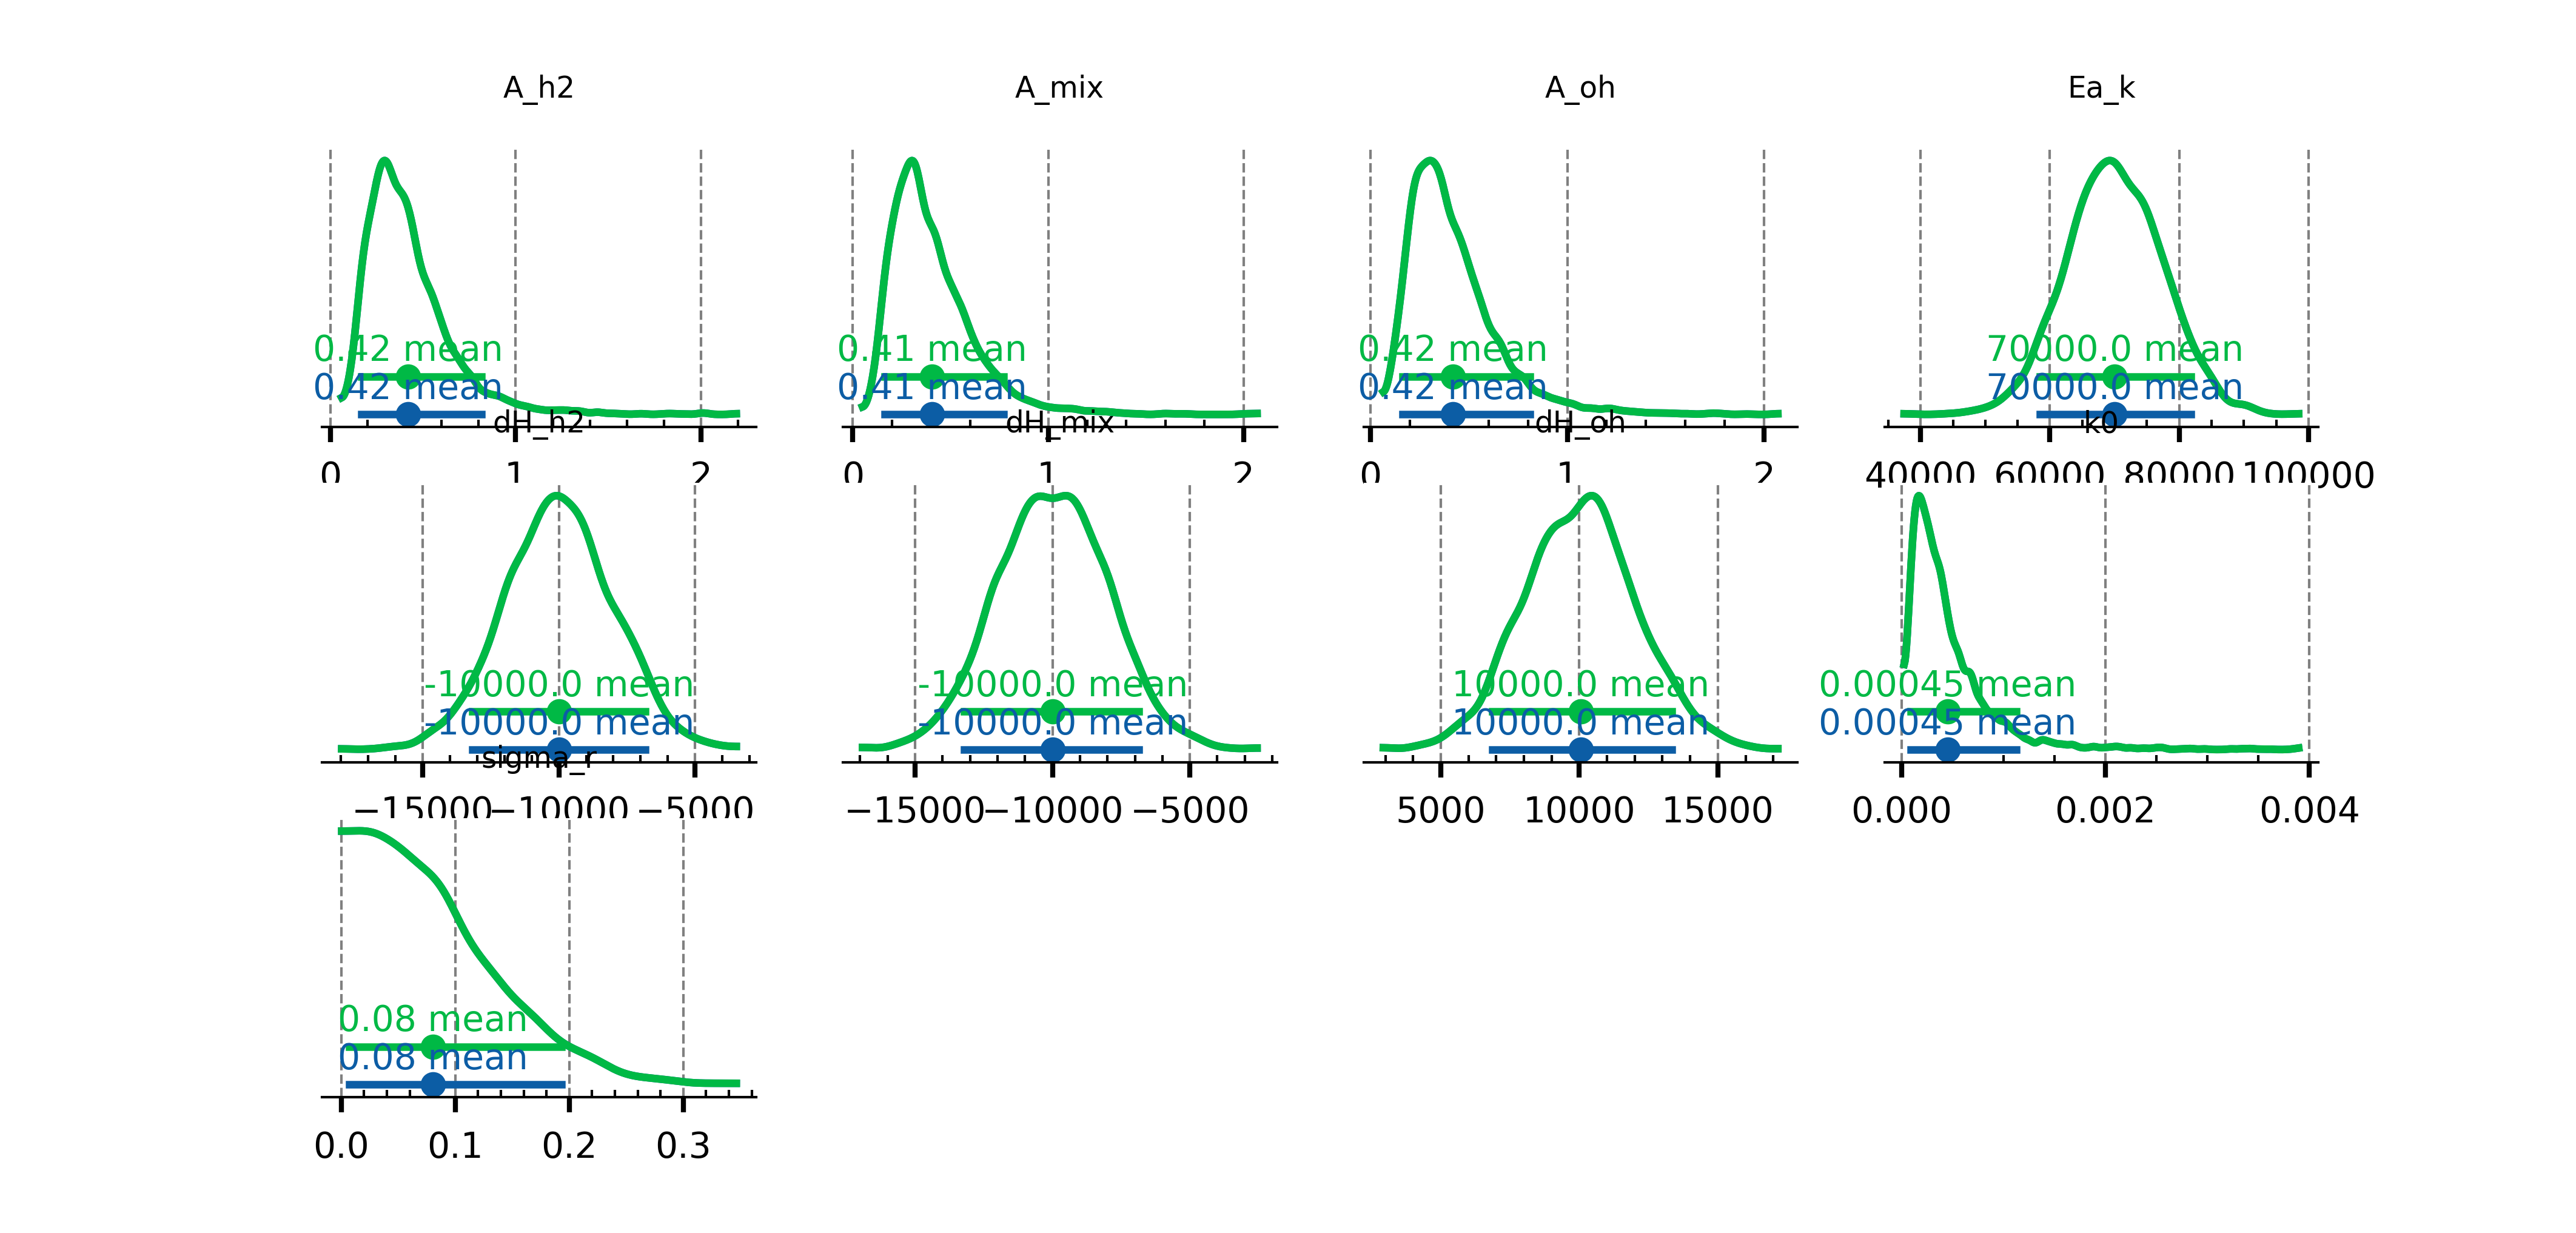

In [10]:
az.plot_dist(
    {
        "paramEKLD iP": ov[2]["idatas"][0],
        "predEKLD ip": ov[3]["idatas"][0],
    },
    var_names=["k0", "Ea_k", "A_oh", "dH_oh", "A_h2", "dH_h2", "A_mix", "dH_mix", "sigma_r"],
    group="prior",
)

## parameter values

In [11]:
import pandas as pd

pd.set_option("display.float_format", lambda x: "%.2e" % x)
for ov_dict in ov:
    print("=" * 40)
    print(f"Results for {ov_dict['ID']} - {ov_dict['DOE']}")
    print("-" * 40)
    sum = (
        az.summary(
            ov_dict["idatas"][0],
            var_names=[
                "k0",
                "Ea_k",
                "A_oh",
                "dH_oh",
                "A_h2",
                "dH_h2",
                "A_mix",
                "dH_mix",
            ],
            round_to=14,
            fmt="wide",
        ),
    )
    # sum[0].to_csv(f"{ov_dict['ID']}_parameter_summary.csv")
    print(sum[0])

Results for B_039 - paramEKLD DOE
----------------------------------------
            mean       sd  eti89_lb  eti89_ub  ess_bulk  ess_tail    r_hat  \
k0      7.26e-04 8.34e-04  3.95e-05  2.31e-03  7.33e+03  7.38e+03 1.00e+00   
Ea_k    6.01e+04 3.05e+04  1.15e+04  1.10e+05  5.90e+03  4.92e+03 1.00e+00   
A_oh    9.93e-01 1.00e+00  5.41e-02  2.93e+00  1.38e+04  8.95e+03 1.00e+00   
dH_oh   1.00e+04 1.01e+04  5.67e+02  2.93e+04  1.51e+04  1.16e+04 1.00e+00   
A_h2    1.25e+00 1.13e+00  8.67e-02  3.39e+00  1.00e+04  7.24e+03 1.00e+00   
dH_h2  -1.03e+04 5.00e+03 -1.82e+04 -2.28e+03  1.85e+04  1.32e+04 1.00e+00   
A_mix   1.13e+00 1.10e+00  6.53e-02  3.23e+00  1.33e+04  8.65e+03 1.00e+00   
dH_mix -1.01e+04 4.95e+03 -1.80e+04 -2.30e+03  2.05e+04  1.82e+04 1.00e+00   

        mcse_mean  mcse_sd  
k0       8.75e-06 1.54e-05  
Ea_k     3.62e+02 2.25e+02  
A_oh     6.04e-03 8.26e-03  
dH_oh    7.18e+01 9.79e+01  
A_h2     9.22e-03 1.12e-02  
dH_h2    3.69e+01 2.61e+01  
A_mix    7.75e-03 1

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:468: UserWarning:

Unscientific behavior. No xlabel provided.

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:503: UserWarning:

Unscientific behavior. No ylabel provided.



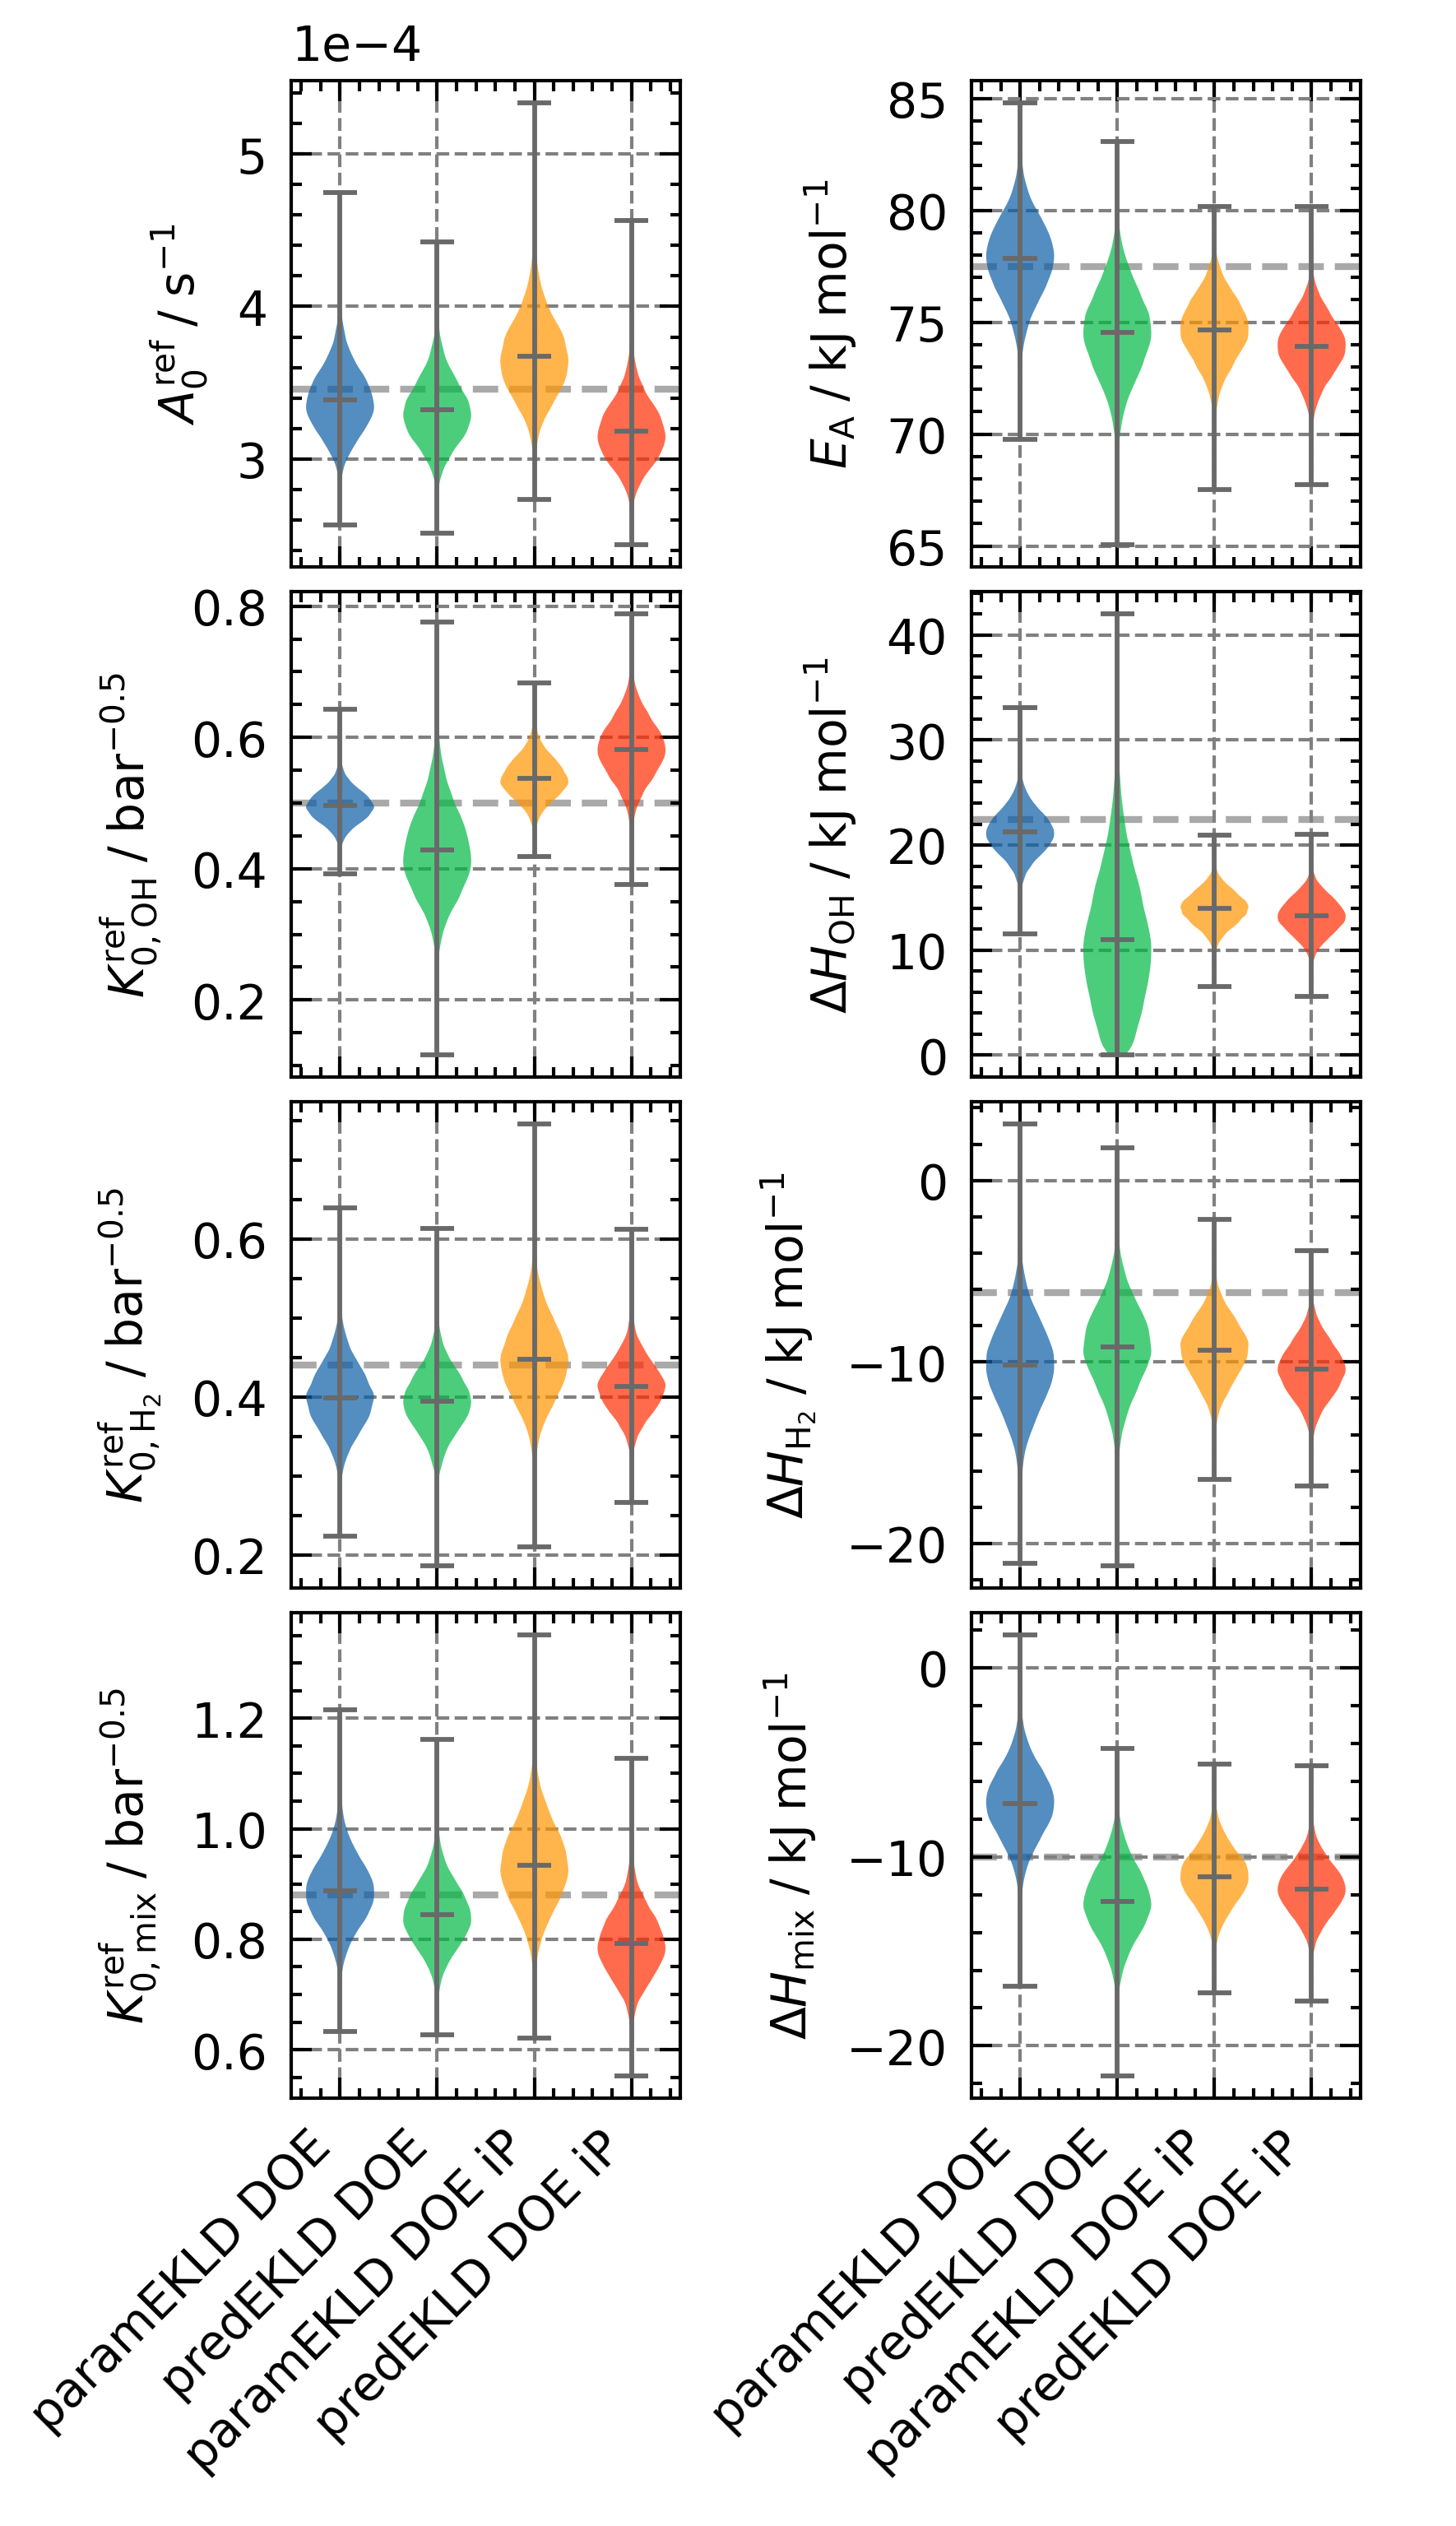

In [12]:
# fig, axes = plt.subplots(4, 2, figsize=(12, 16))
fig = ICIW_Plots.figure(layout="single_column", height=13 * ICIW_Plots.cm2inch)
axes = ICIW_Plots.make_rect_subplots(
    fig,
    ax_width=2.0 * ICIW_Plots.cm2inch,
    ax_layout=(4, 2),
    ax_height=2.5 * ICIW_Plots.cm2inch,
    h_sep=1.5 * ICIW_Plots.cm2inch,
    # sharex=True,
    left_h=1.5 * ICIW_Plots.cm2inch,
    bottom_v=2.2 * ICIW_Plots.cm2inch,
)
axes = axes.flatten()

param_names = ["k0", "Ea_k", "A_oh", "dH_oh", "A_h2", "dH_h2", "A_mix", "dH_mix"]

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}
labeldict = {
    "k0": r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$",
    "Ea_k": r"$E_\mathrm{A}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_oh": r"$K_{0,\mathrm{OH}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_oh": r"$\Delta H_\mathrm{OH}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_h2": r"$K_{0,\mathrm{H_2}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_h2": r"$\Delta H_\mathrm{H_2}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_mix": r"$K_{0,\mathrm{mix}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_mix": r"$\Delta H_\mathrm{mix}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
}

for idx, param in enumerate(param_names):
    ax = axes[idx]

    # Collect samples for each DOE method
    violin_data = []
    labels = []

    for i, ov_dict in enumerate(ov):
        # Get final posterior samples for this parameter
        samples = ov_dict["idatas"][-1].posterior[param].values.flatten()
        if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
            samples = samples * 1e-3  # Convert to kJ/mol for better readability
        violin_data.append(samples)
        labels.append(ov_dict["DOE"])

    # Create violin plot
    parts = ax.violinplot(
        violin_data,
        positions=range(len(ov)),
        showmeans=True,
        # showmedians=True,
        widths=0.7,
    )

    # Make violin lines thinner
    for partname in ("cbars", "cmins", "cmaxes", "cmeans", "cmedians"):
        if partname in parts:

            parts[partname].set_color("dimgrey")
            parts[partname].set_linewidth(0.7)

    # Color the violins
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for i, pc in enumerate(parts["bodies"]):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)
        # pc.set_linewidth(1.0)

    # Plot ground truth
    true_val = TRUE_PARAMS[keydict[param]]
    if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
        true_val = true_val * 1e-3  # Convert to kJ/mol for better readability
    ax.axhline(
        y=true_val,
        color="darkgrey",
        linestyle="--",
        linewidth=1.0,
        label="Ground Truth",
        zorder=0,
    )

    ax.set_ylabel(f"{labeldict[param]}")
    ax.set_xticks(range(len(ov)))

    # Only show x-axis labels in the last row (indices 6 and 7)
    if idx >= 6:
        ax.set_xticklabels(
            [ov_dict["DOE"] for ov_dict in ov],
            rotation=45,
            ha="right",
        )
    else:
        ax.set_xticklabels([])

    # ax.grid(True, alpha=0.3)
    # ax.legend(loc="best")
    # ax.set_title(f"{keydict[param]}")

    # Adjust x-axis limits
    ax.set_xlim(-0.5, len(ov) - 0.5)

axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

# plt.tight_layout()
# plt.savefig("figures/KinFit_parameter_comparison.png")
# plt.savefig("figures/KinFit_parameter_comparison.svg")
# plt.savefig("figures/KinFit_parameter_comparison.pdf")
plt.show()

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:468: UserWarning:

Unscientific behavior. No xlabel provided.

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:503: UserWarning:

Unscientific behavior. No ylabel provided.

/tmp/ipykernel_163439/391212938.py:120: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



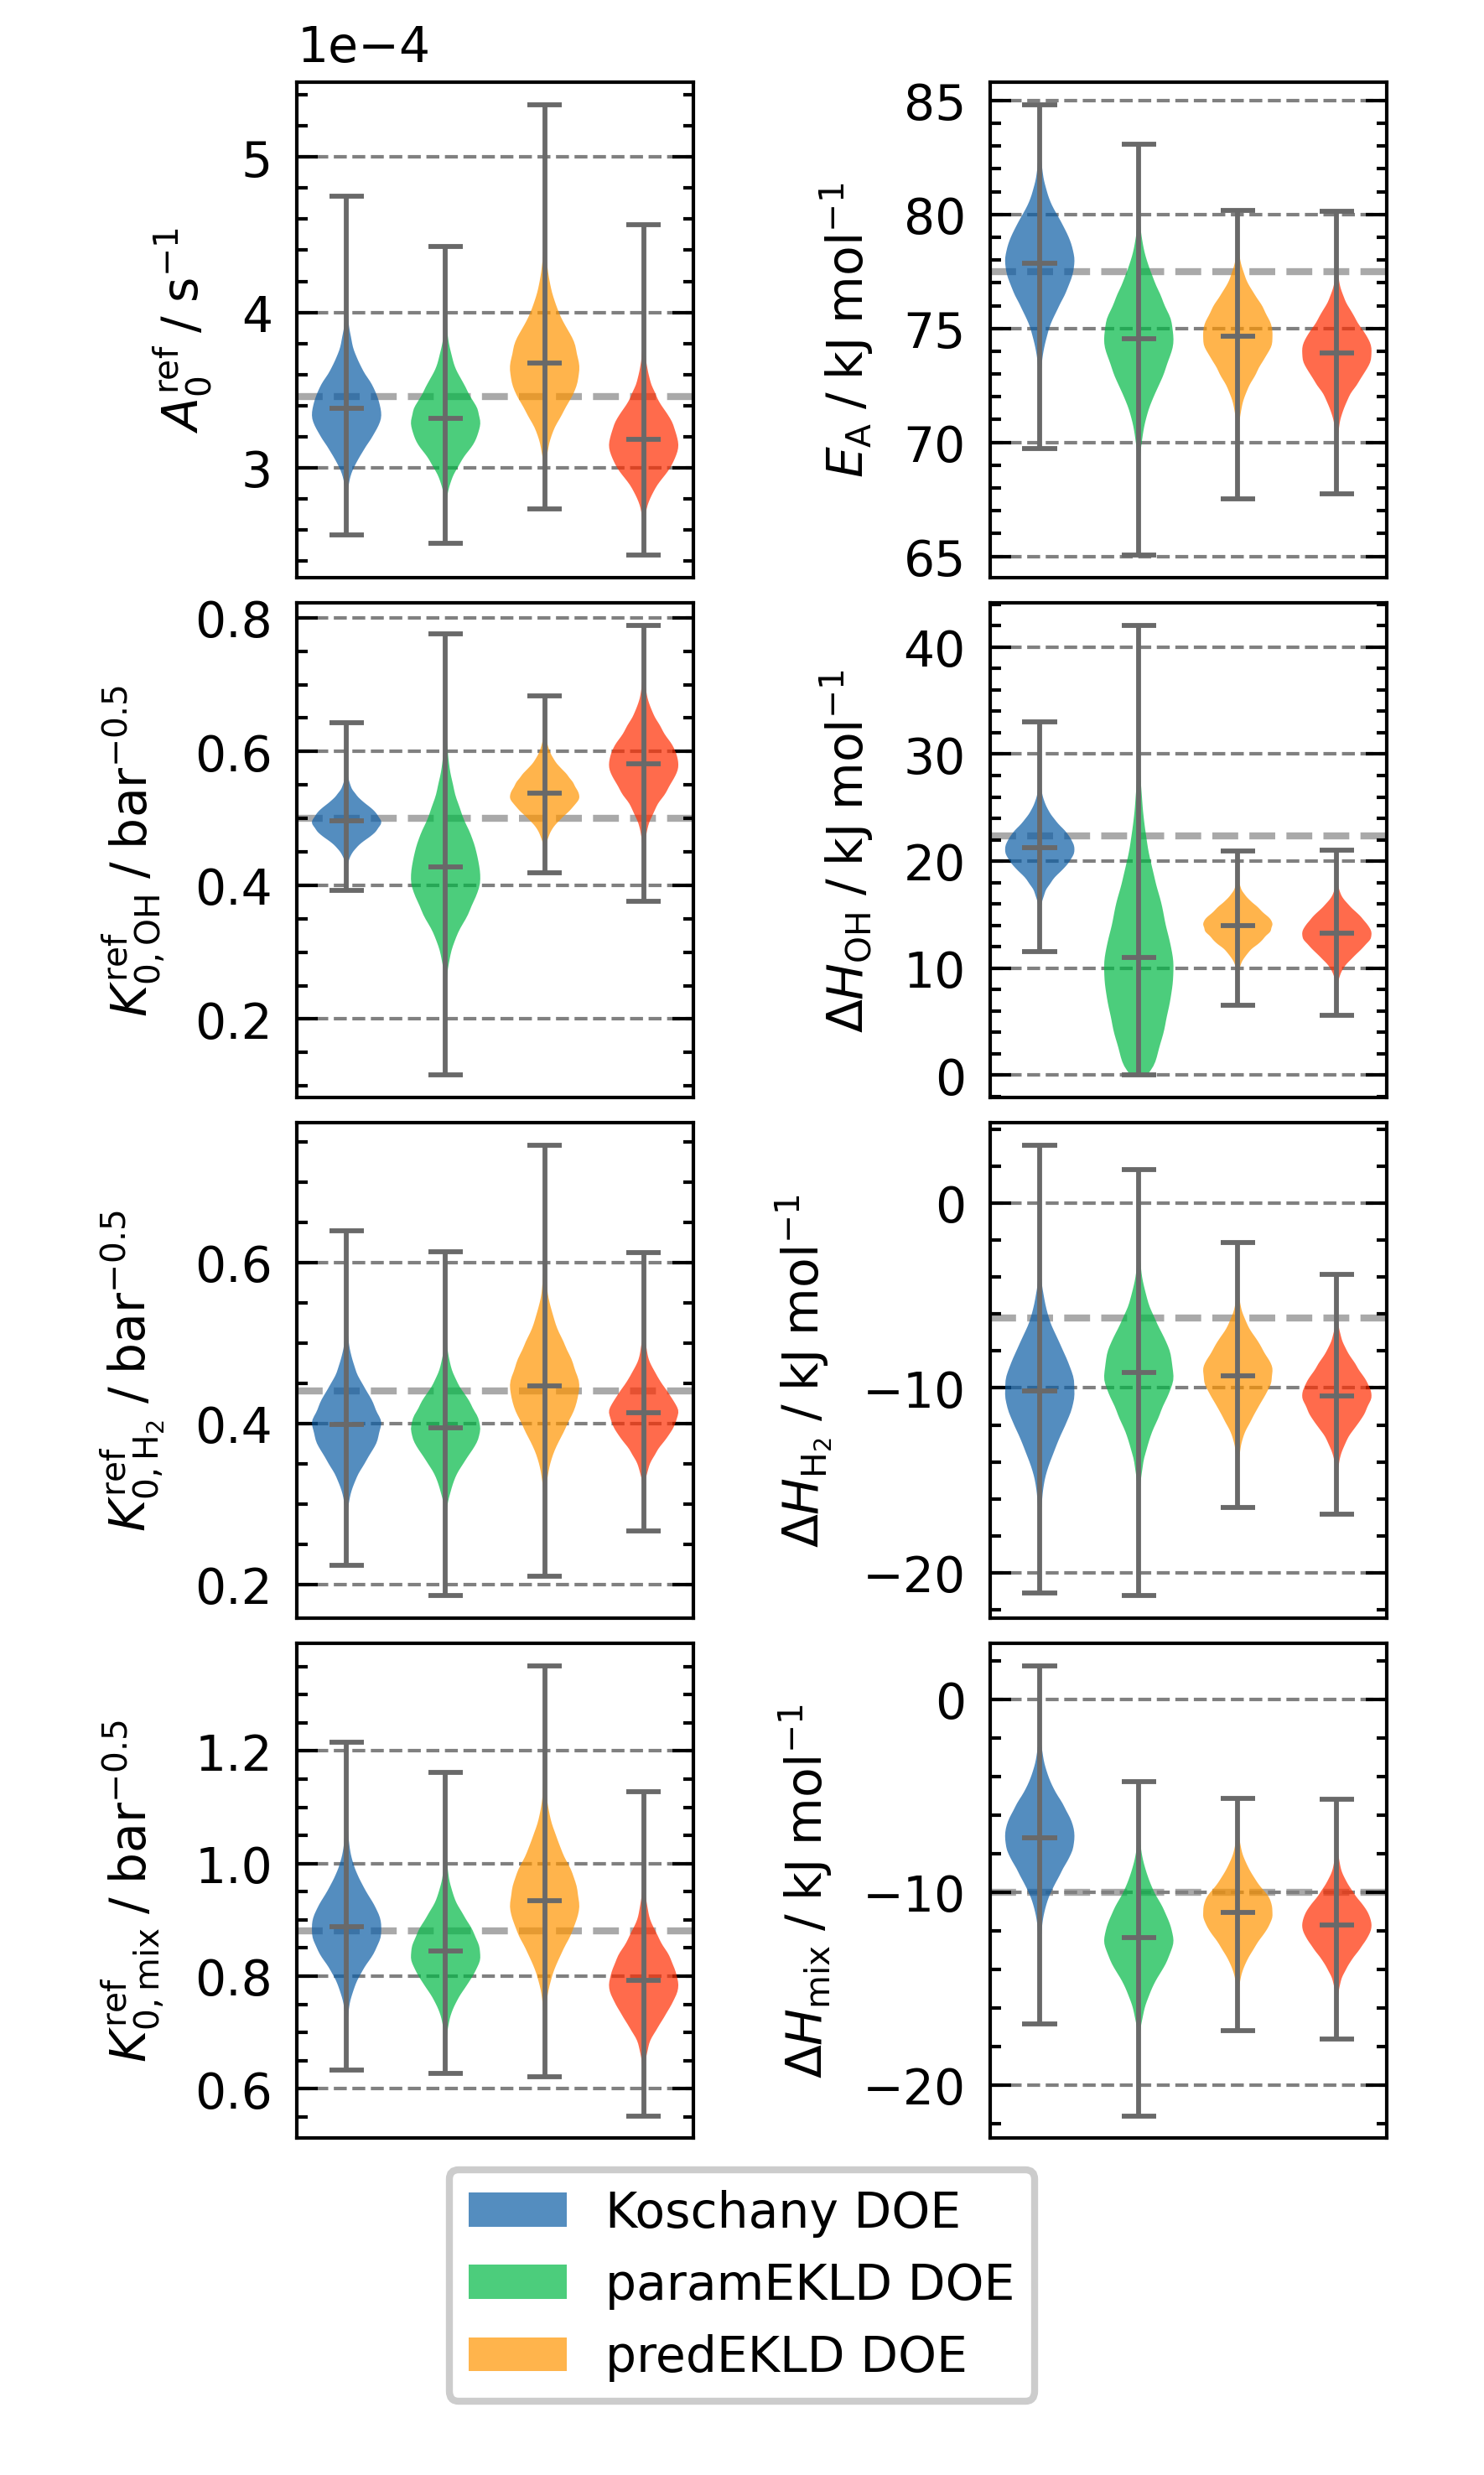

In [13]:
# fig, axes = plt.subplots(4, 2, figsize=(12, 16))
fig = ICIW_Plots.figure(layout="single_column", height=12.5 * ICIW_Plots.cm2inch)
axes = ICIW_Plots.make_rect_subplots(
    fig,
    ax_width=2.0 * ICIW_Plots.cm2inch,
    ax_layout=(4, 2),
    ax_height=2.5 * ICIW_Plots.cm2inch,
    h_sep=1.5 * ICIW_Plots.cm2inch,
    # sharex=True,
    left_h=1.5 * ICIW_Plots.cm2inch,
    bottom_v=1.7 * ICIW_Plots.cm2inch,
)
axes = axes.flatten()

param_names = ["k0", "Ea_k", "A_oh", "dH_oh", "A_h2", "dH_h2", "A_mix", "dH_mix"]

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}
labeldict = {
    "k0": r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$",
    "Ea_k": r"$E_\mathrm{A}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_oh": r"$K_{0,\mathrm{OH}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_oh": r"$\Delta H_\mathrm{OH}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_h2": r"$K_{0,\mathrm{H_2}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_h2": r"$\Delta H_\mathrm{H_2}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_mix": r"$K_{0,\mathrm{mix}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_mix": r"$\Delta H_\mathrm{mix}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
}

for idx, param in enumerate(param_names):
    ax = axes[idx]

    # Collect samples for each DOE method
    violin_data = []
    labels = []

    for i, ov_dict in enumerate(ov):
        # Get final posterior samples for this parameter
        samples = ov_dict["idatas"][-1].posterior[param].values.flatten()
        if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
            samples = samples * 1e-3  # Convert to kJ/mol for better readability
        violin_data.append(samples)
        labels.append(ov_dict["DOE"])

    # Create violin plot
    parts = ax.violinplot(
        violin_data,
        positions=range(len(ov)),
        showmeans=True,
        # showmedians=True,
        widths=0.7,
    )

    # Make violin lines thinner
    for partname in ("cbars", "cmins", "cmaxes", "cmeans", "cmedians"):
        if partname in parts:

            parts[partname].set_color("dimgrey")
            parts[partname].set_linewidth(0.7)

    # Color the violins
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for i, pc in enumerate(parts["bodies"]):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)
        # pc.set_linewidth(1.0)

    # Plot ground truth
    true_val = TRUE_PARAMS[keydict[param]]
    if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
        true_val = true_val * 1e-3  # Convert to kJ/mol for better readability
    ax.axhline(
        y=true_val,
        color="darkgrey",
        linestyle="--",
        linewidth=1.0,
        label="Ground Truth",
        zorder=0,
    )

    ax.set_ylabel(f"{labeldict[param]}")

    # Remove x-axis ticks and labels
    ax.set_xticks([])
    ax.set_xticklabels([])

    # Remove x-axis grid
    ax.grid(False, axis="x")

    # Adjust x-axis limits
    ax.set_xlim(-0.5, len(ov) - 0.5)

axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

# Create legend with DOE methods centered beneath the plots
from matplotlib.patches import Patch

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
legend_elements = [
    Patch(facecolor=colors[0], alpha=0.7, label="Koschany DOE"),
    Patch(facecolor=colors[1], alpha=0.7, label="paramEKLD DOE"),
    Patch(facecolor=colors[2], alpha=0.7, label="predEKLD DOE"),
]
fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=1,
    frameon=True,
    bbox_to_anchor=(0.5, 0.02),
)

plt.tight_layout()
# plt.savefig("figures/KinFit_parameter_comparison.png")
# plt.savefig("figures/KinFit_parameter_comparison.svg")
# plt.savefig("figures/KinFit_parameter_comparison.pdf")
plt.show()

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:468: UserWarning:

Unscientific behavior. No xlabel provided.

/home/hannes/Environments/.BIBOvenv/lib/python3.12/site-packages/ICIW_Plots/layout.py:503: UserWarning:

Unscientific behavior. No ylabel provided.

/tmp/ipykernel_163439/3041408562.py:120: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



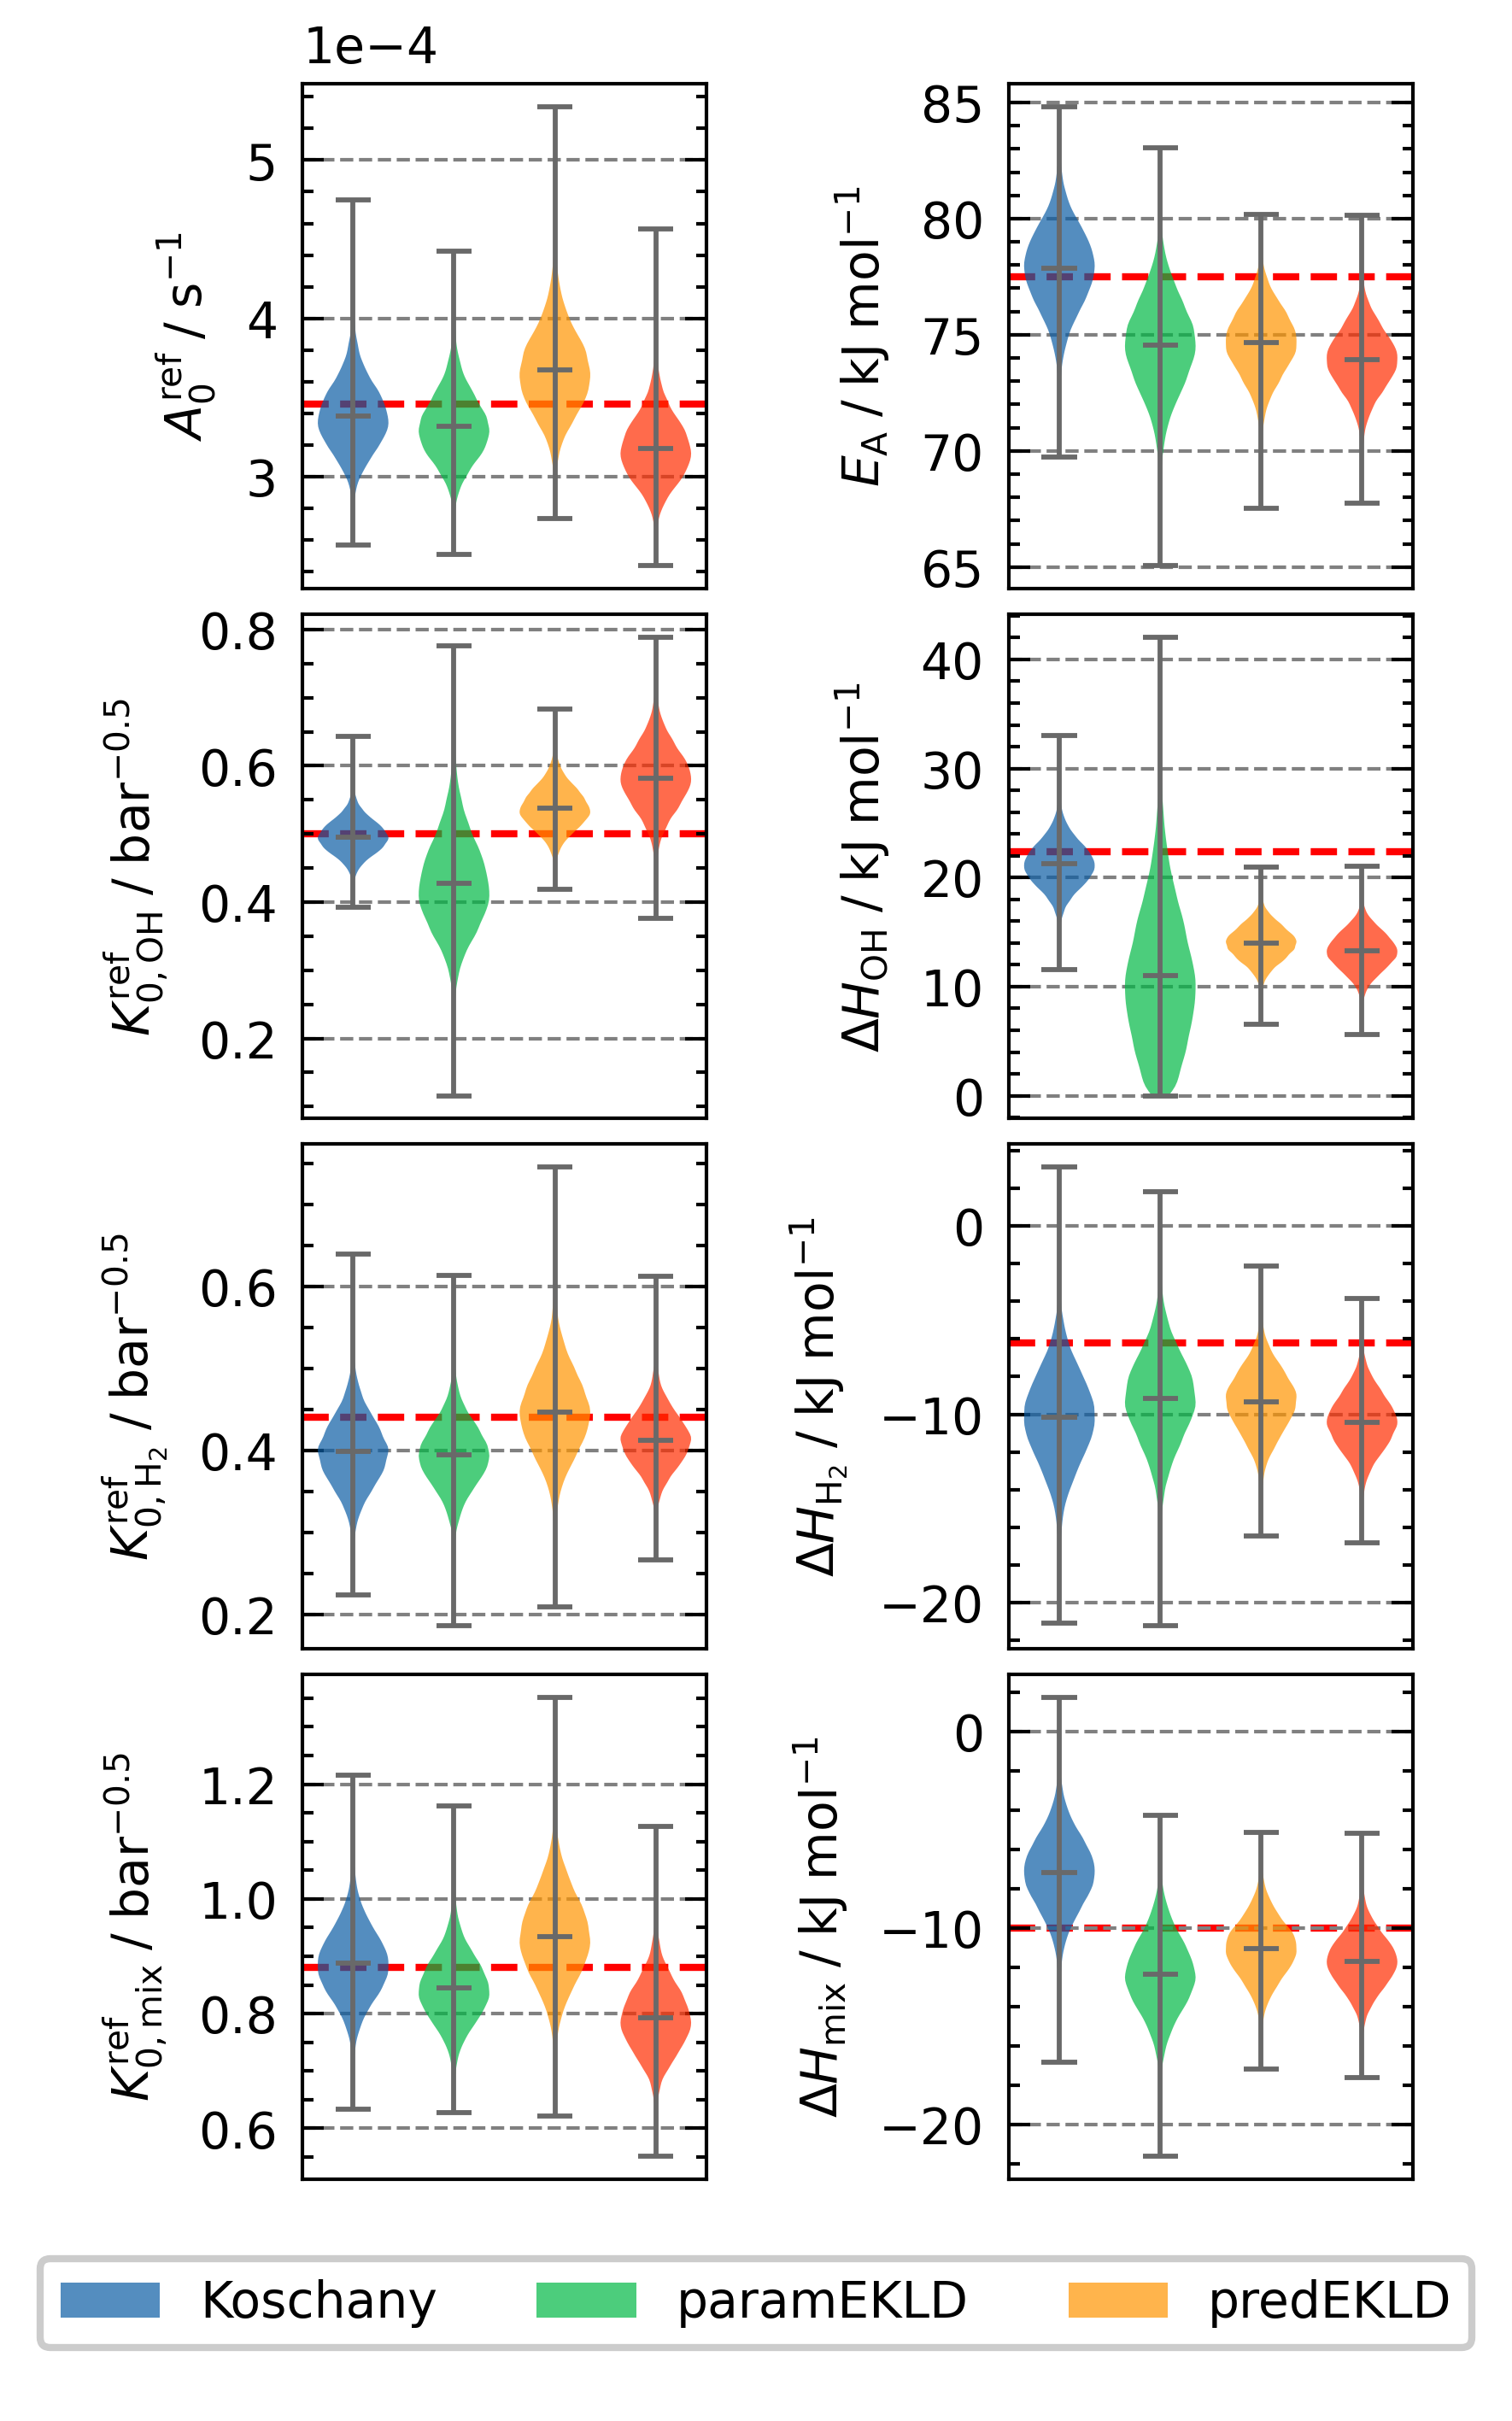

In [14]:
# fig, axes = plt.subplots(4, 2, figsize=(12, 16))
fig = ICIW_Plots.figure(layout="single_column", height=12 * ICIW_Plots.cm2inch)
axes = ICIW_Plots.make_rect_subplots(
    fig,
    ax_width=2.0 * ICIW_Plots.cm2inch,
    ax_layout=(4, 2),
    ax_height=2.5 * ICIW_Plots.cm2inch,
    h_sep=1.5 * ICIW_Plots.cm2inch,
    # sharex=True,
    left_h=1.5 * ICIW_Plots.cm2inch,
    bottom_v=1.2 * ICIW_Plots.cm2inch,
)
axes = axes.flatten()

param_names = ["k0", "Ea_k", "A_oh", "dH_oh", "A_h2", "dH_h2", "A_mix", "dH_mix"]

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}
labeldict = {
    "k0": r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$",
    "Ea_k": r"$E_\mathrm{A}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_oh": r"$K_{0,\mathrm{OH}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_oh": r"$\Delta H_\mathrm{OH}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_h2": r"$K_{0,\mathrm{H_2}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_h2": r"$\Delta H_\mathrm{H_2}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
    "A_mix": r"$K_{0,\mathrm{mix}}^\mathrm{ref}\;/\; \mathrm{bar}^{-0.5}$",
    "dH_mix": r"$\Delta H_\mathrm{mix}\;/\;\mathrm{kJ}\;\mathrm{mol}^{-1}$",
}

for idx, param in enumerate(param_names):
    ax = axes[idx]

    # Collect samples for each DOE method
    violin_data = []
    labels = []

    for i, ov_dict in enumerate(ov):
        # Get final posterior samples for this parameter
        samples = ov_dict["idatas"][-1].posterior[param].values.flatten()
        if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
            samples = samples * 1e-3  # Convert to kJ/mol for better readability
        violin_data.append(samples)
        labels.append(ov_dict["DOE"])

    # Create violin plot
    parts = ax.violinplot(
        violin_data,
        positions=range(len(ov)),
        showmeans=True,
        # showmedians=True,
        widths=0.7,
    )

    # Make violin lines thinner
    for partname in ("cbars", "cmins", "cmaxes", "cmeans", "cmedians"):
        if partname in parts:

            parts[partname].set_color("dimgrey")
            parts[partname].set_linewidth(0.7)

    # Color the violins
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for i, pc in enumerate(parts["bodies"]):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)
        # pc.set_linewidth(1.0)

    # Plot ground truth
    true_val = TRUE_PARAMS[keydict[param]]
    if param in ["Ea_k", "dH_oh", "dH_h2", "dH_mix"]:
        true_val = true_val * 1e-3  # Convert to kJ/mol for better readability
    ax.axhline(
        y=true_val,
        color="red",
        linestyle="--",
        linewidth=1.0,
        label="Ground Truth",
        zorder=0,
    )

    ax.set_ylabel(f"{labeldict[param]}")

    # Remove x-axis ticks and labels
    ax.set_xticks([])
    ax.set_xticklabels([])

    # Remove x-axis grid
    ax.grid(False, axis="x")

    # Adjust x-axis limits
    ax.set_xlim(-0.5, len(ov) - 0.5)

axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

# Create legend with DOE methods centered beneath the plots
from matplotlib.patches import Patch

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
legend_elements = [
    Patch(facecolor=colors[0], alpha=0.7, label="Koschany"),
    Patch(facecolor=colors[1], alpha=0.7, label="paramEKLD"),
    Patch(facecolor=colors[2], alpha=0.7, label="predEKLD"),
]
fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=3,
    frameon=True,
    bbox_to_anchor=(0.5, 0.02),
)

plt.tight_layout()
# plt.savefig("figures/KinFit_parameter_comparison.png")
# plt.savefig("figures/KinFit_parameter_comparison.svg")
# plt.savefig("figures/KinFit_parameter_comparison.pdf")
plt.show()

### Predictive accuracy

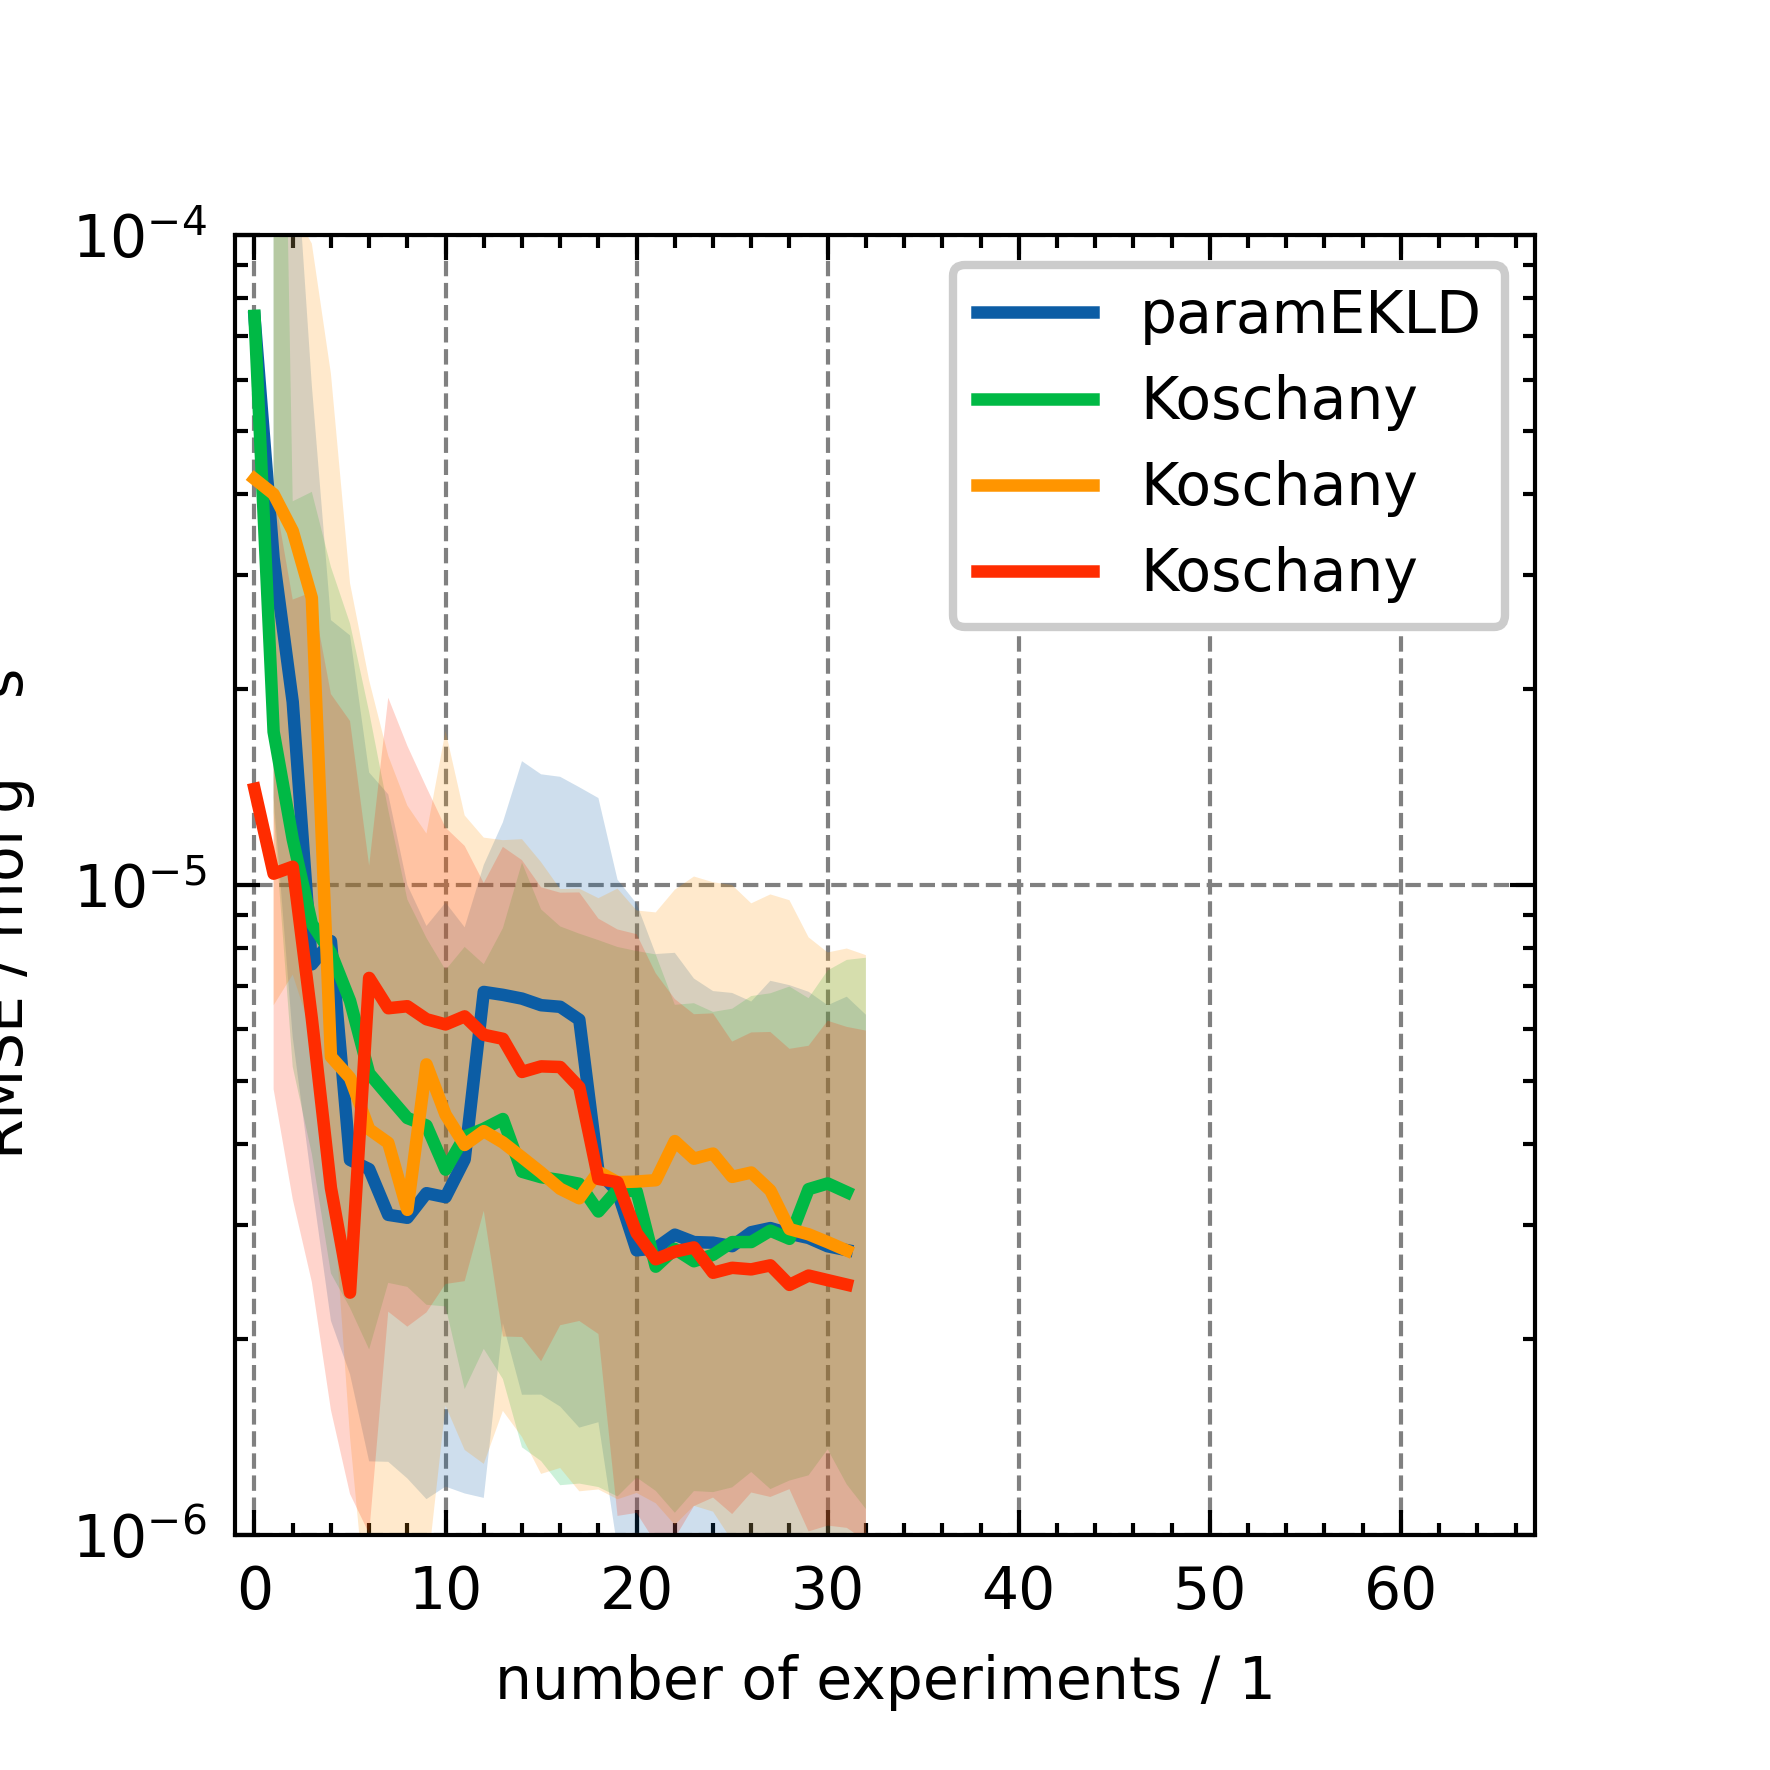

In [15]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(1e-6, 1e-4),
    xlim=(-1, 67),
)

for ov_dict in ov:
    if ov_dict["DOE"] == "predEKLD DOE":
        label = "predEKLD"
    if ov_dict["DOE"] == "paramEKLD DOE":
        label = "paramEKLD"
    else:
        label = "Koschany"
    ax.plot(
        np.median(ov_dict["RMSEs"], axis=1),
        label=label,
    )
    ax.fill_between(
        np.arange(1, len(ov_dict["RMSEs"]) + 1),
        np.quantile(ov_dict["RMSEs"], 0.025, axis=1),
        np.quantile(ov_dict["RMSEs"], 0.975, axis=1),
        alpha=0.2,
        ls="--",
        # edgecolor="gray",
    )
    ax.legend(frameon=True)

# plt.savefig("B_042_RMSE.png", dpi=600, bbox_inches="tight")

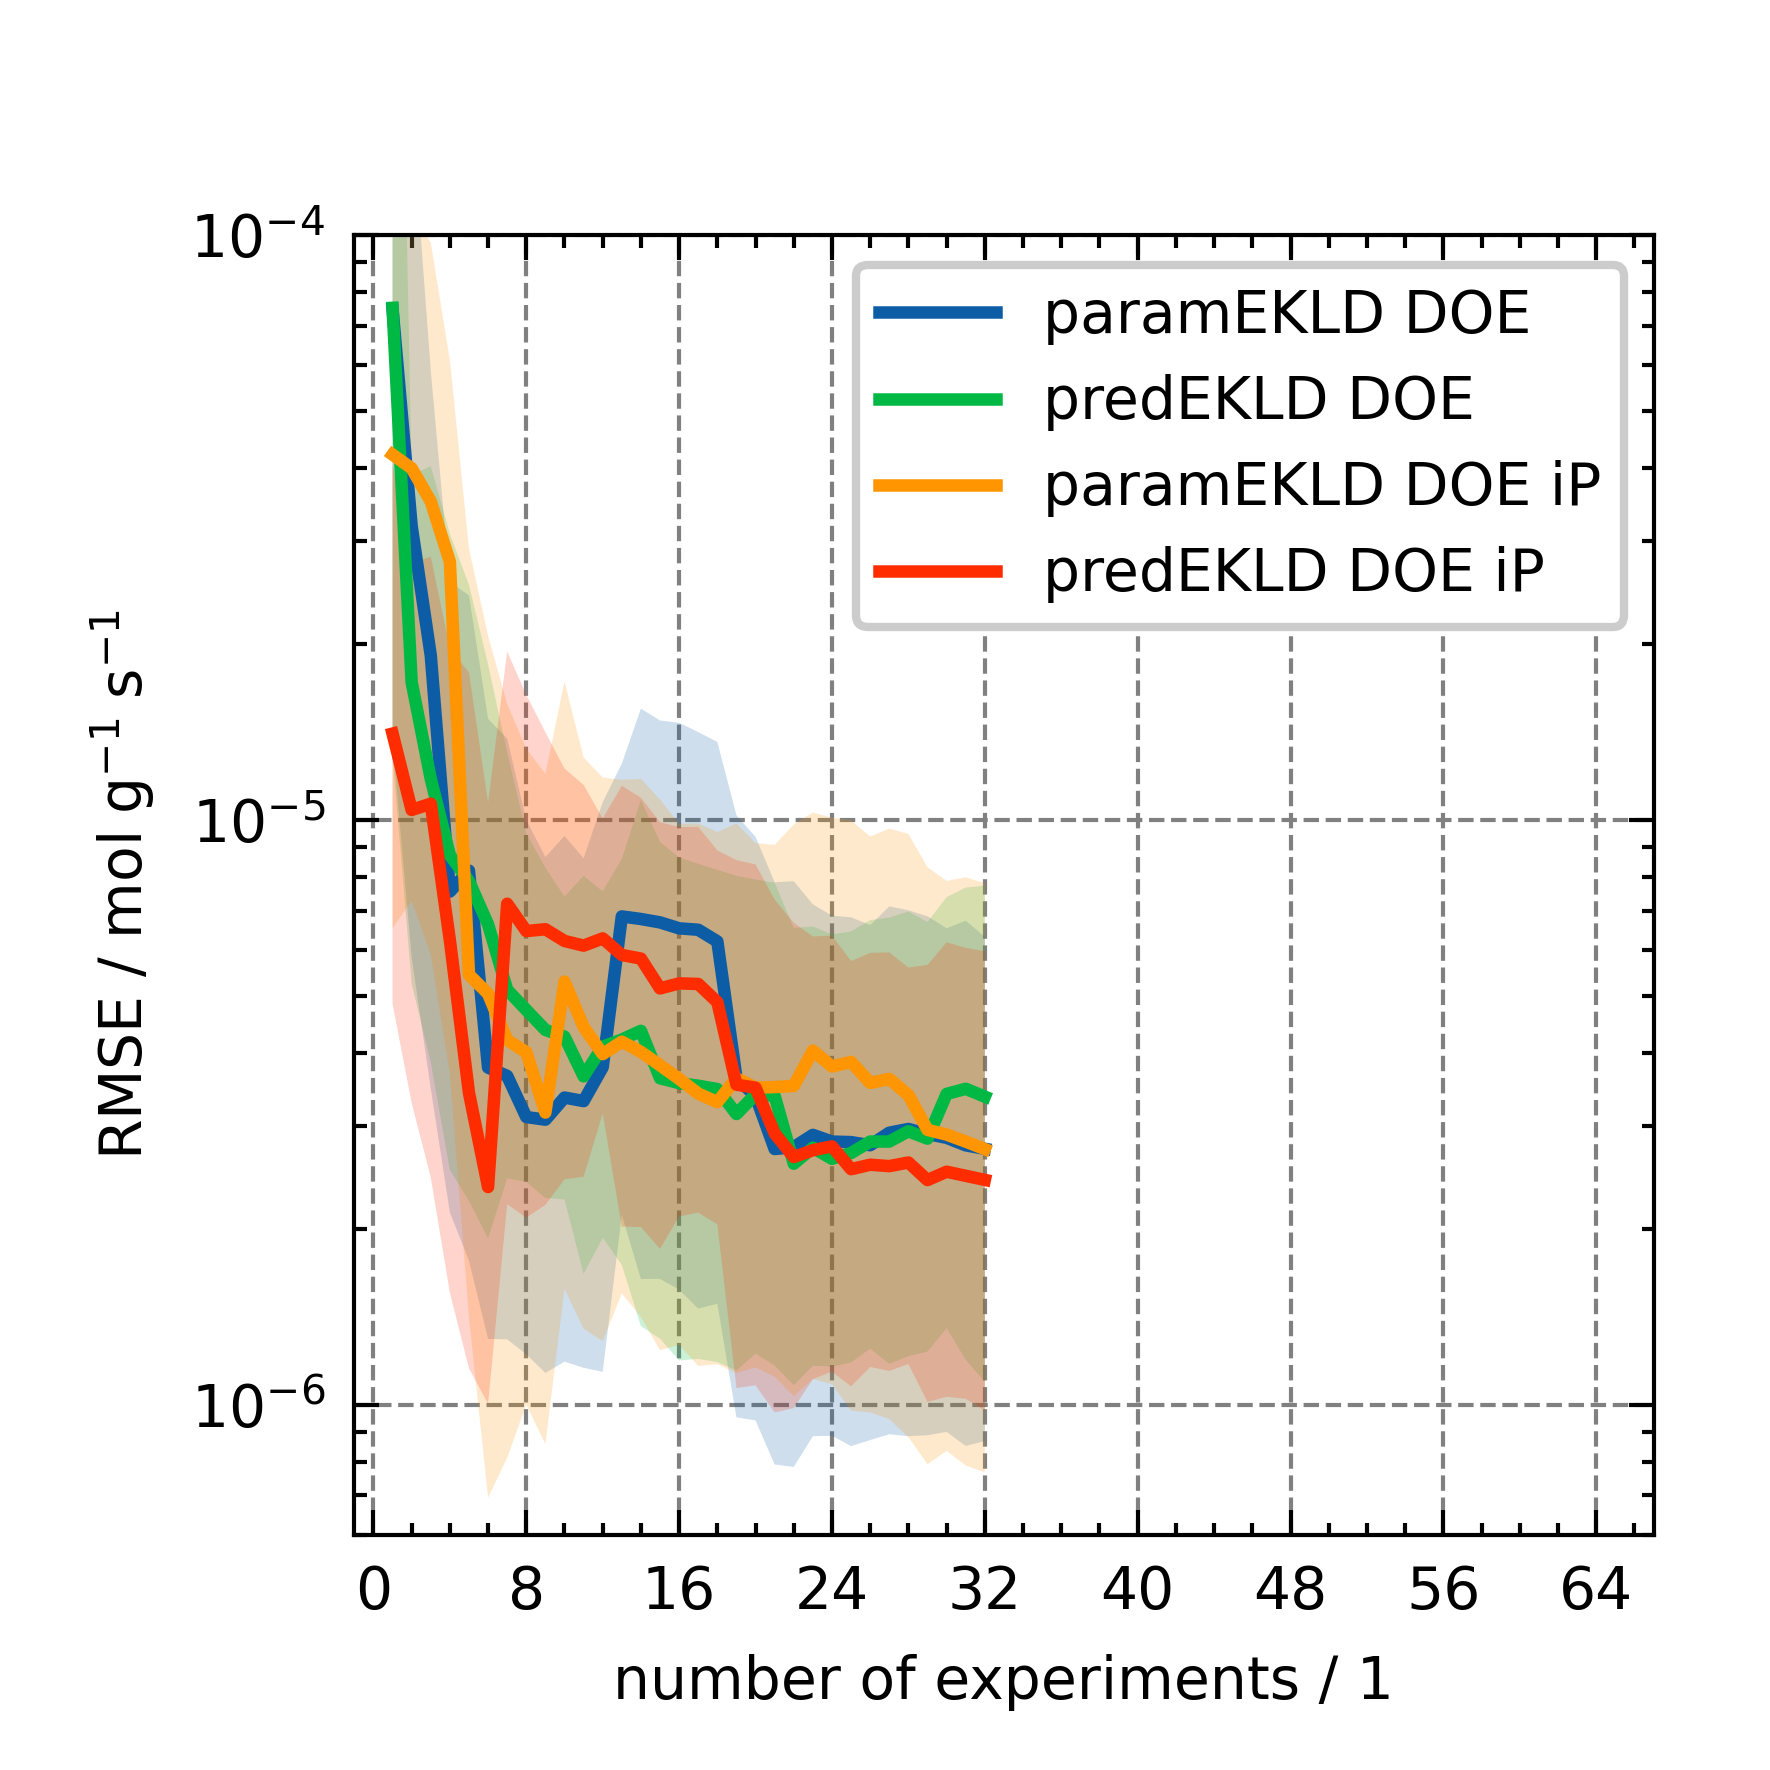

In [16]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
    left_h=1.5 * ICIW_Plots.cm2inch,
)

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, ov_dict in enumerate(ov):
    if ov_dict["DOE"] == "Koschany DOE":
        ax.hlines(
            np.median(ov_dict["RMSEs"], axis=1)[-1],
            xmin=-1,
            xmax=64,
            label=ov_dict["DOE"],
            ls="--",
            color=colors[i],
        )
        ax.fill_between(
            np.arange(-1, len(ov_dict["RMSEs"]) + 1),
            np.quantile(ov_dict["RMSEs"], 0.025, axis=1)[-1],
            np.quantile(ov_dict["RMSEs"], 0.975, axis=1)[-1],
            alpha=0.2,
            # ls="--",
            facecolor=colors[i],
            # edgecolor="gray",
        )
        continue
    ax.plot(
        np.arange(1, len(ov_dict["RMSEs"]) + 1),
        np.median(ov_dict["RMSEs"], axis=1),
        # "o--",
        # ms=4,
        # lw=1,
        label=ov_dict["DOE"],
        color=colors[i],
    )
    ax.fill_between(
        np.arange(1, len(ov_dict["RMSEs"]) + 1),
        np.quantile(ov_dict["RMSEs"], 0.025, axis=1),
        np.quantile(ov_dict["RMSEs"], 0.975, axis=1),
        alpha=0.2,
        # ls="--",
        facecolor=colors[i],
        # edgecolor="gray",
    )
    ax.legend(frameon=True)

# plt.savefig("figures/KinFit_RMSE.png")
# plt.savefig("figures/KinFit_RMSE.pdf")
# plt.savefig("figures/KinFit_RMSE.svg")

(32, 2)
(32, 2)
(32, 2)
(32, 2)


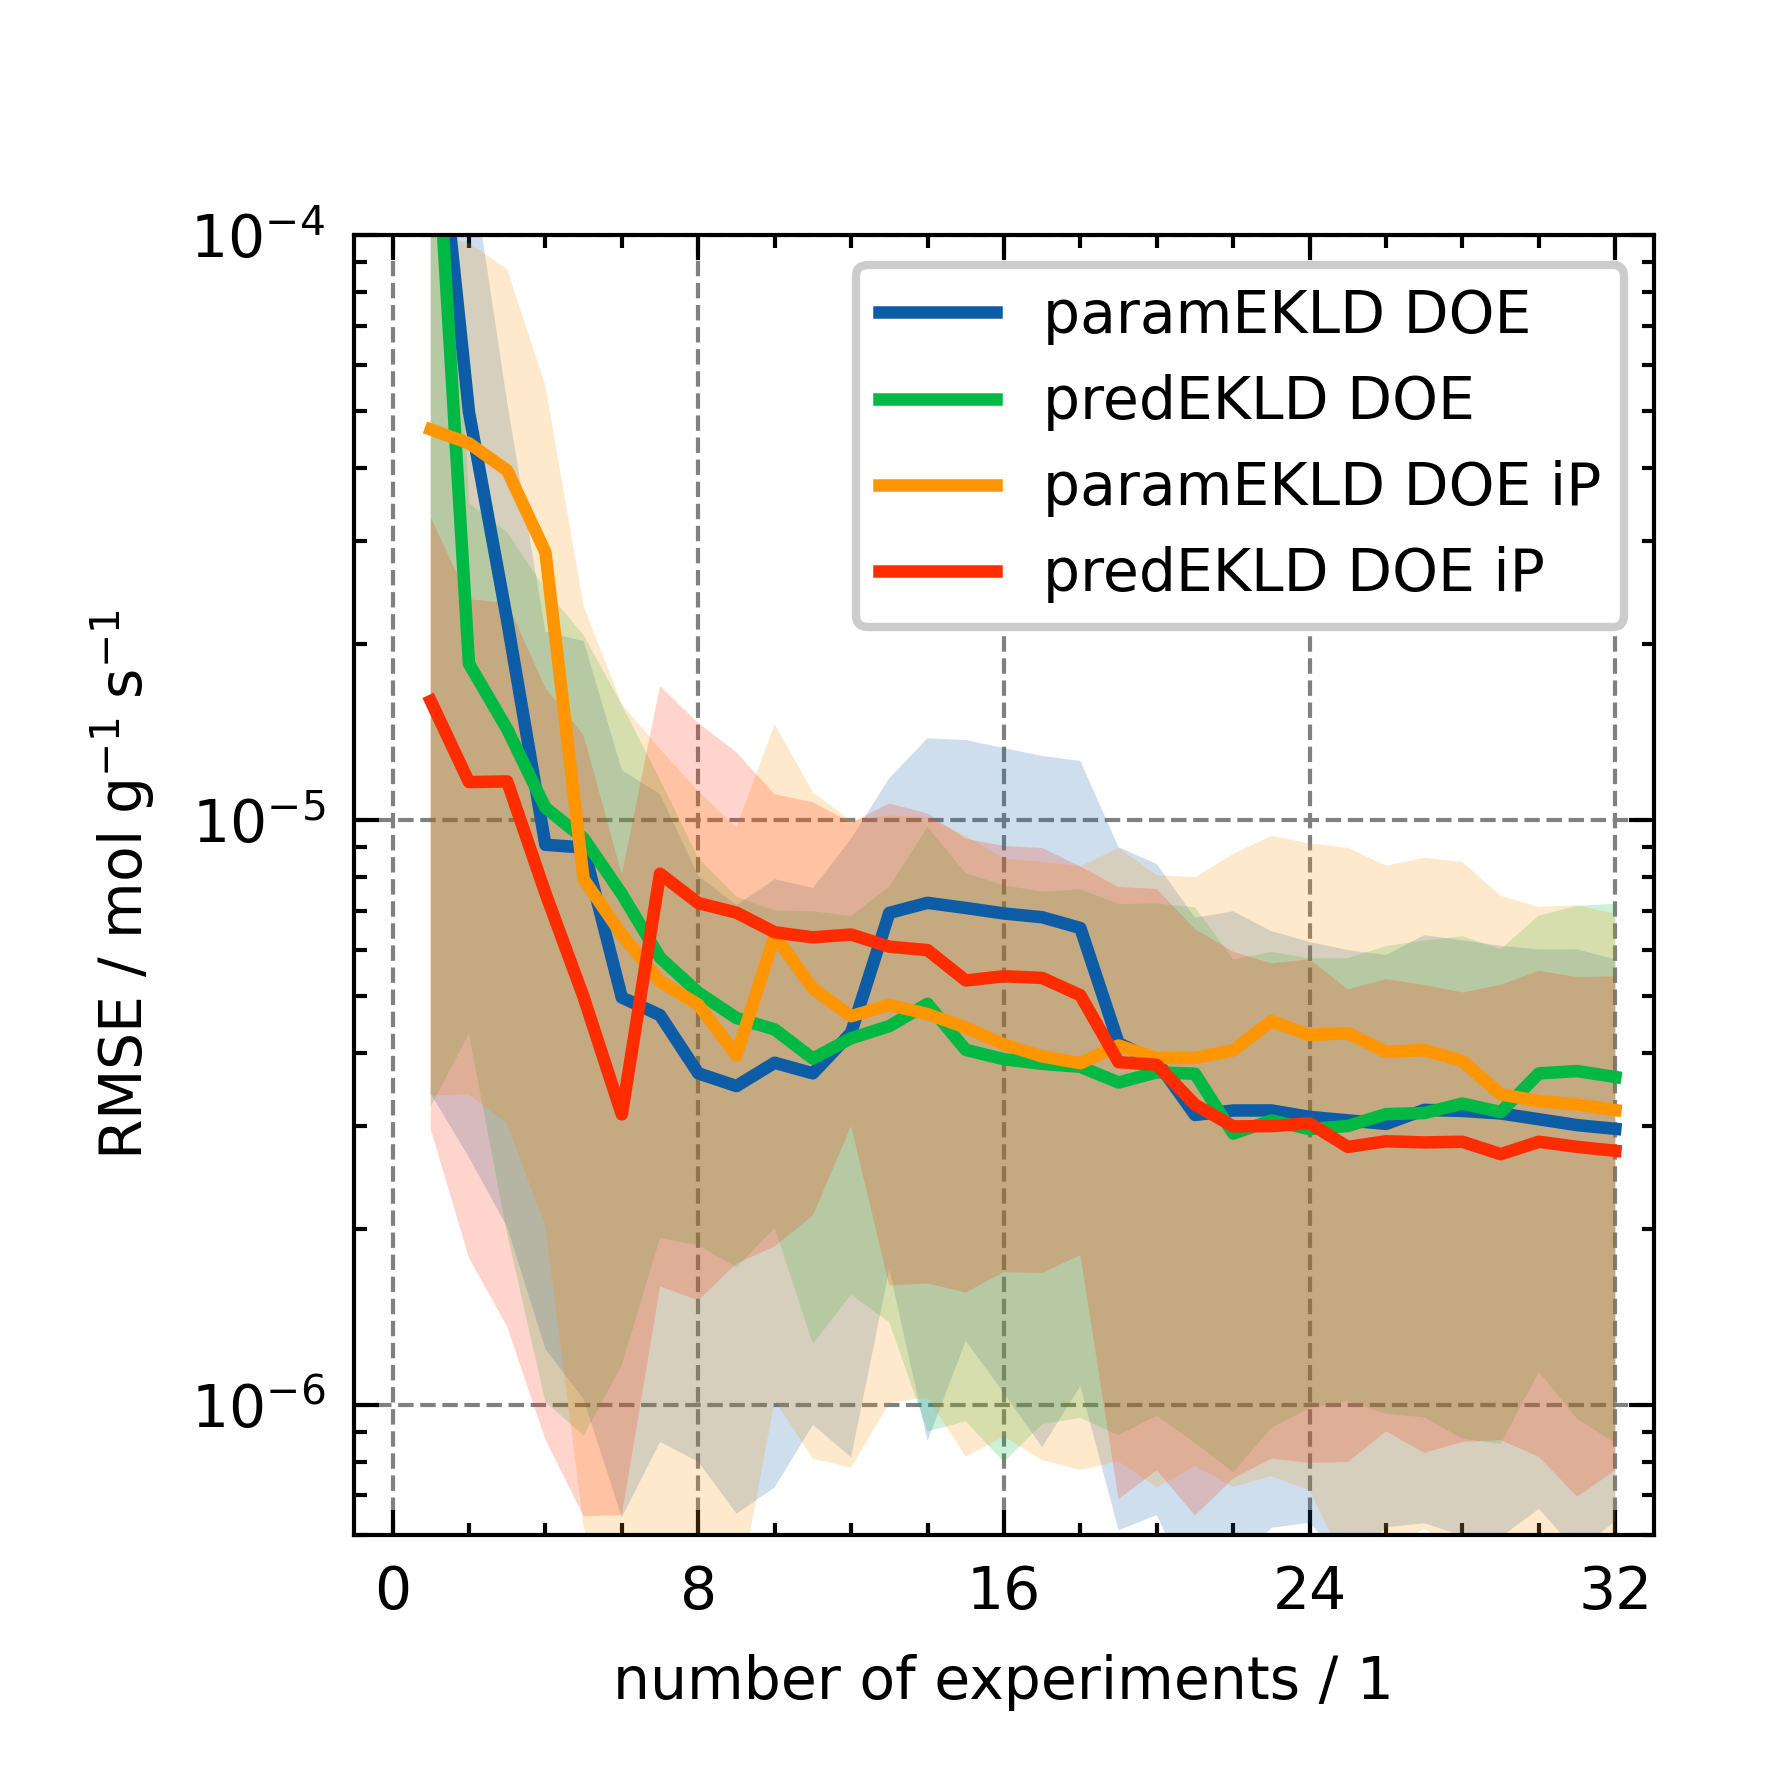

In [29]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(6e-7, 1e-4),
    xlim=(-1, 33),
    xticks=[0, 8, 16, 24, 32],
    left_h=1.5 * ICIW_Plots.cm2inch,
)

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for i, ov_dict in enumerate(ov):
    if ov_dict["DOE"] == "Koschany DOE":
        ax.hlines(
            np.mean(ov_dict["RMSEs"], axis=1)[-1],
            xmin=-1,
            xmax=64,
            label=ov_dict["DOE"],
            ls="--",
            color=colors[i],
        )
        HDI = az.hdi(ov_dict["RMSEs"][-1], prob=0.95)
        ax.fill_between(
            np.arange(-1, len(ov_dict["RMSEs"]) + 1),
            HDI[0],
            HDI[1],
            alpha=0.2,
            # ls="--",
            facecolor=colors[i],
            # edgecolor="gray",
        )
        continue
    ax.plot(
        np.arange(1, len(ov_dict["RMSEs"]) + 1),
        np.mean(ov_dict["RMSEs"], axis=1),
        # "o--",
        # ms=4,
        # lw=1,
        label=ov_dict["DOE"],
        color=colors[i],
    )
    HDI = az.hdi(ov_dict["RMSEs"], prob=0.95)
    print(HDI.shape)
    ax.fill_between(
        np.arange(1, len(ov_dict["RMSEs"]) + 1),
        HDI[:, 0],
        HDI[:, 1],
        alpha=0.2,
        # ls="--",
        facecolor=colors[i],
        # edgecolor="gray",
    )
    ax.legend(frameon=True)

plt.savefig("figures/KinFit_RMSE_iP.png")
plt.savefig("figures/KinFit_RMSE_iP.pdf")
plt.savefig("figures/KinFit_RMSE_iP.svg")

### Information Gain

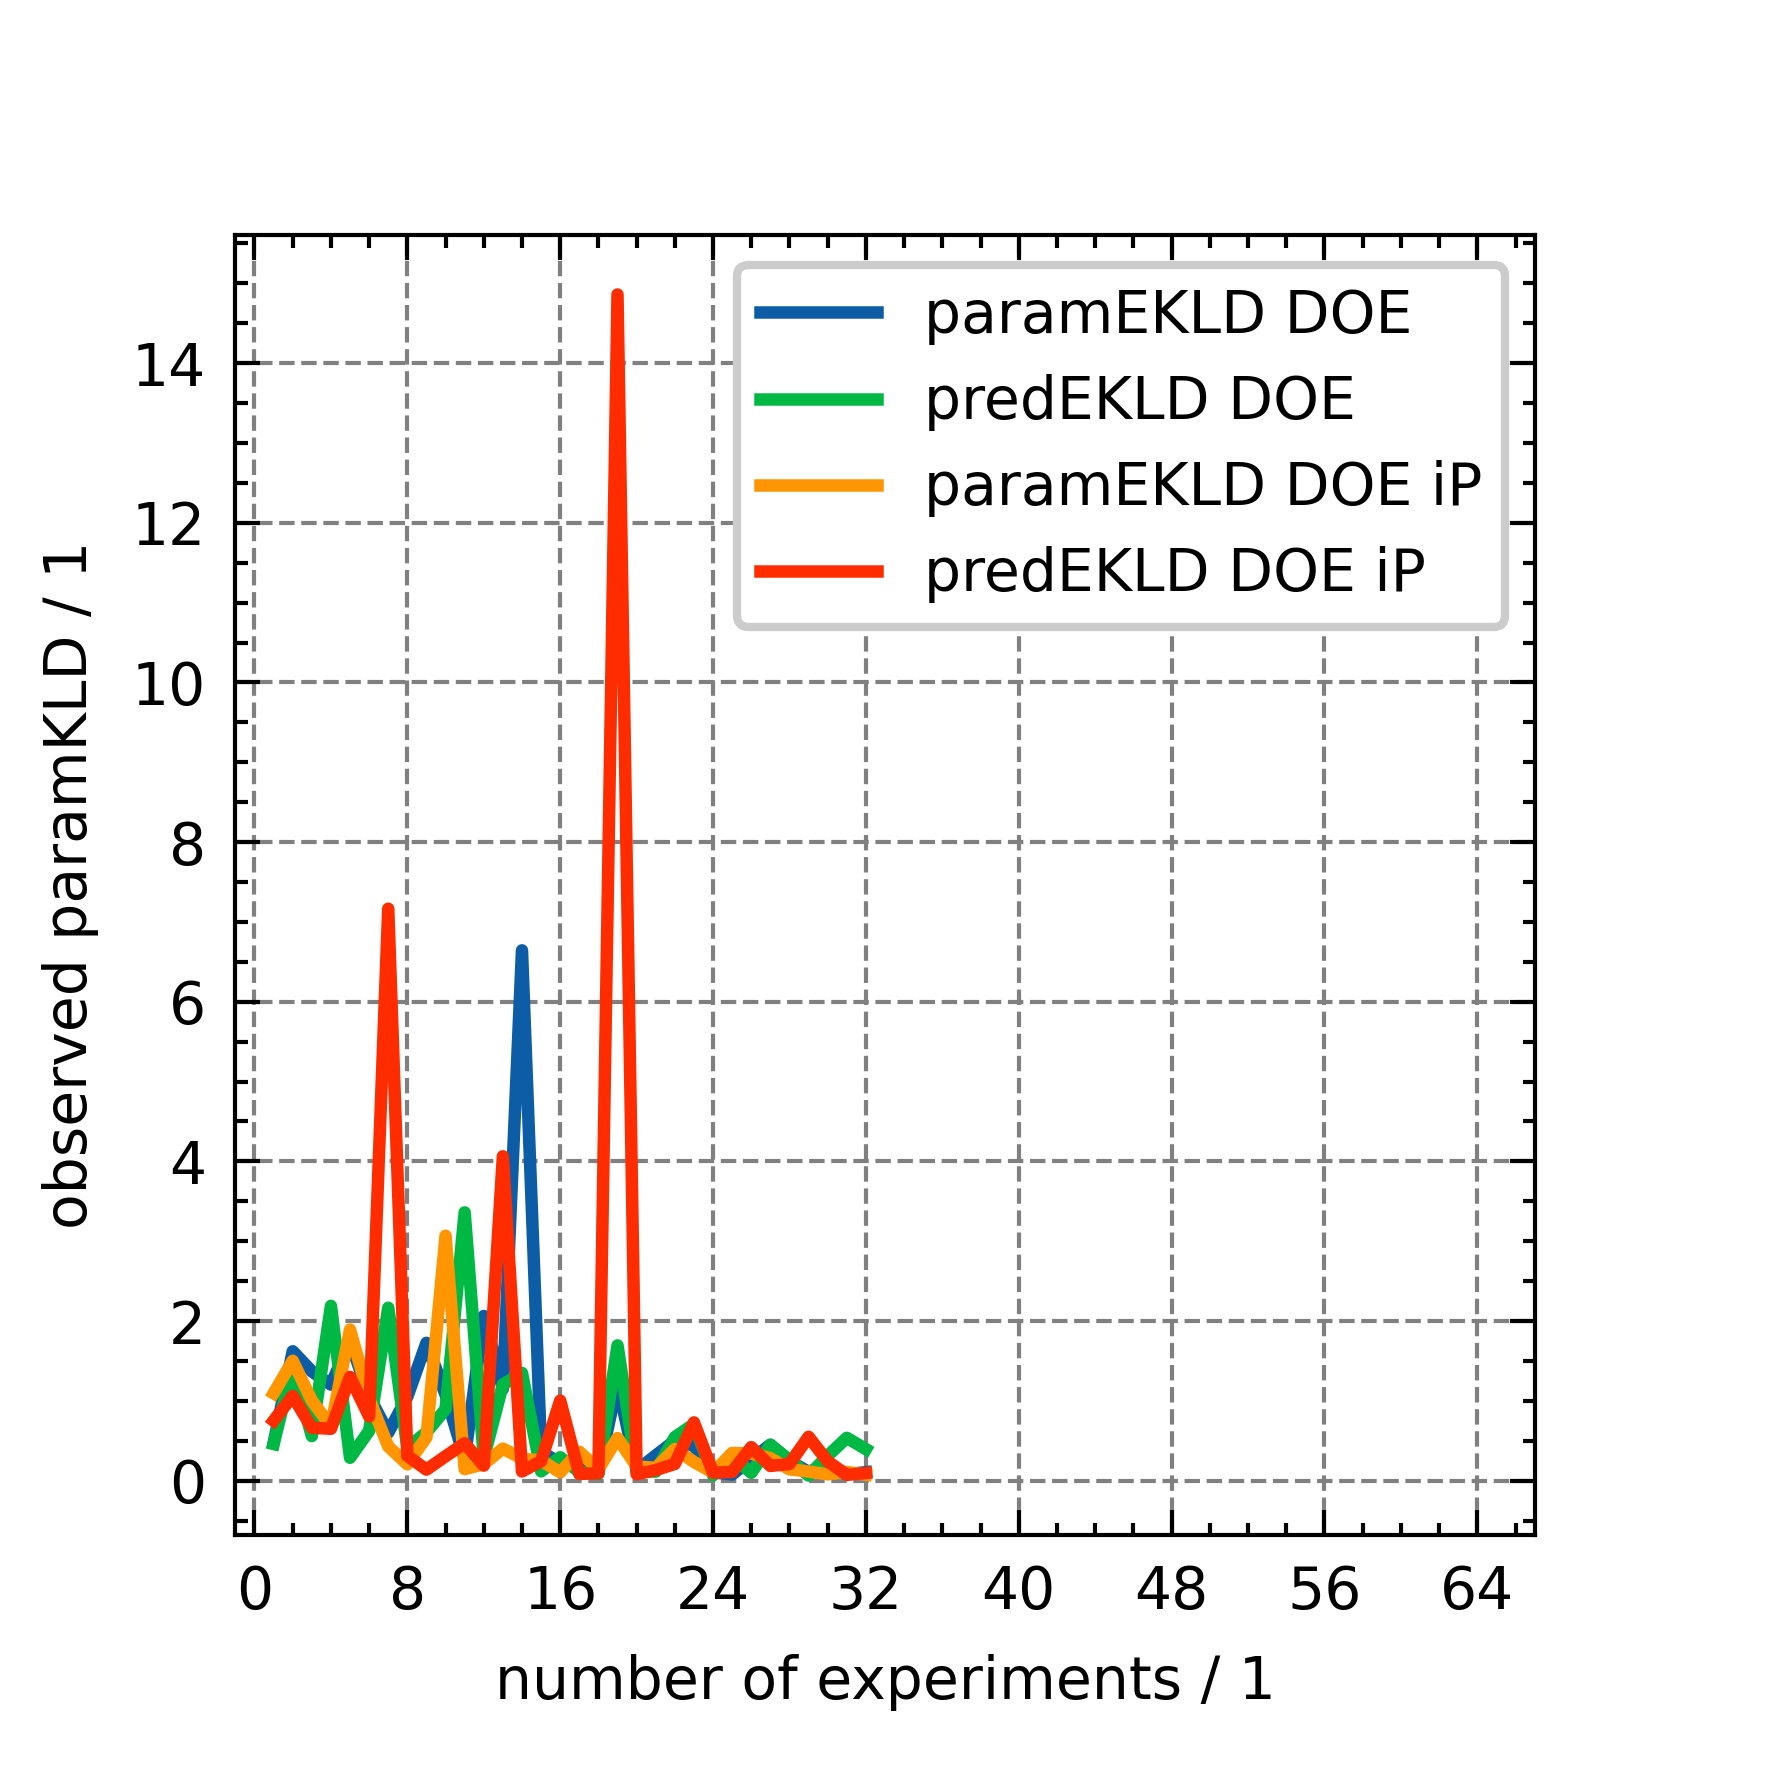

In [18]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel="observed paramKLD / 1",
    # ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
)
for i, ov_dict in enumerate(ov):
    ax.plot(
        np.arange(len(ov_dict["paramEKLDS"])) + 1,
        ov_dict["paramEKLDS"],
        label=ov_dict["DOE"],
    )
    ax.legend()

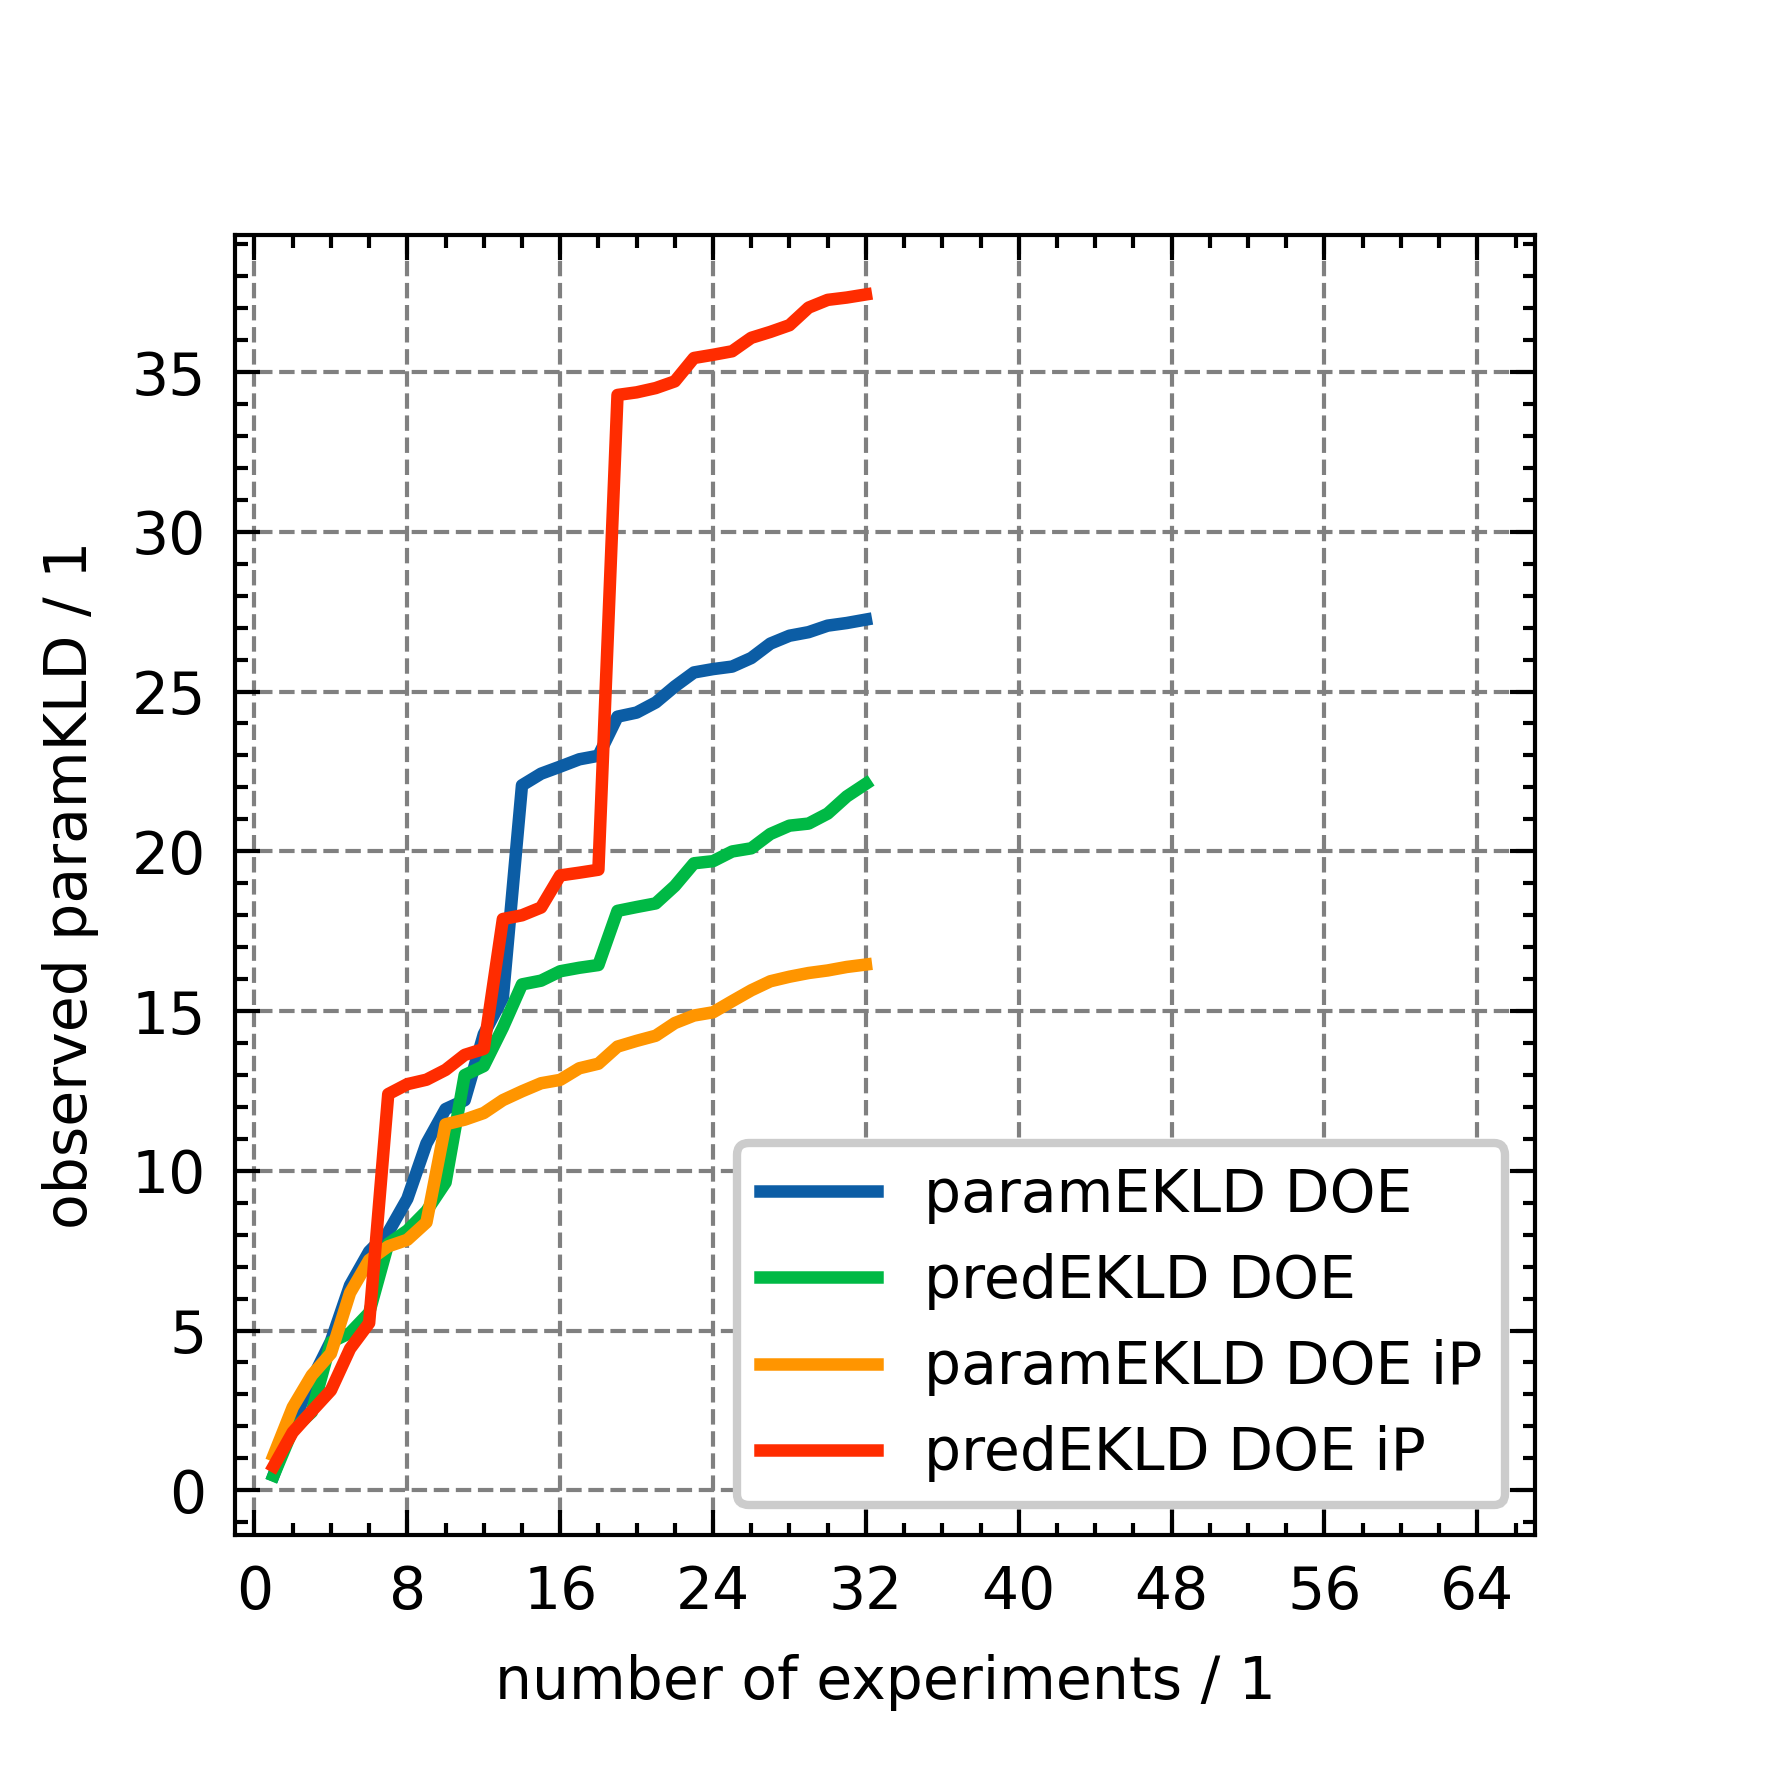

In [19]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel="observed paramKLD / 1",
    # ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
)
for i, ov_dict in enumerate(ov):
    ax.plot(
        np.arange(len(ov_dict["paramEKLDS"])) + 1,
        np.cumsum(ov_dict["paramEKLDS"]),
        label=ov_dict["DOE"],
    )
    ax.legend()

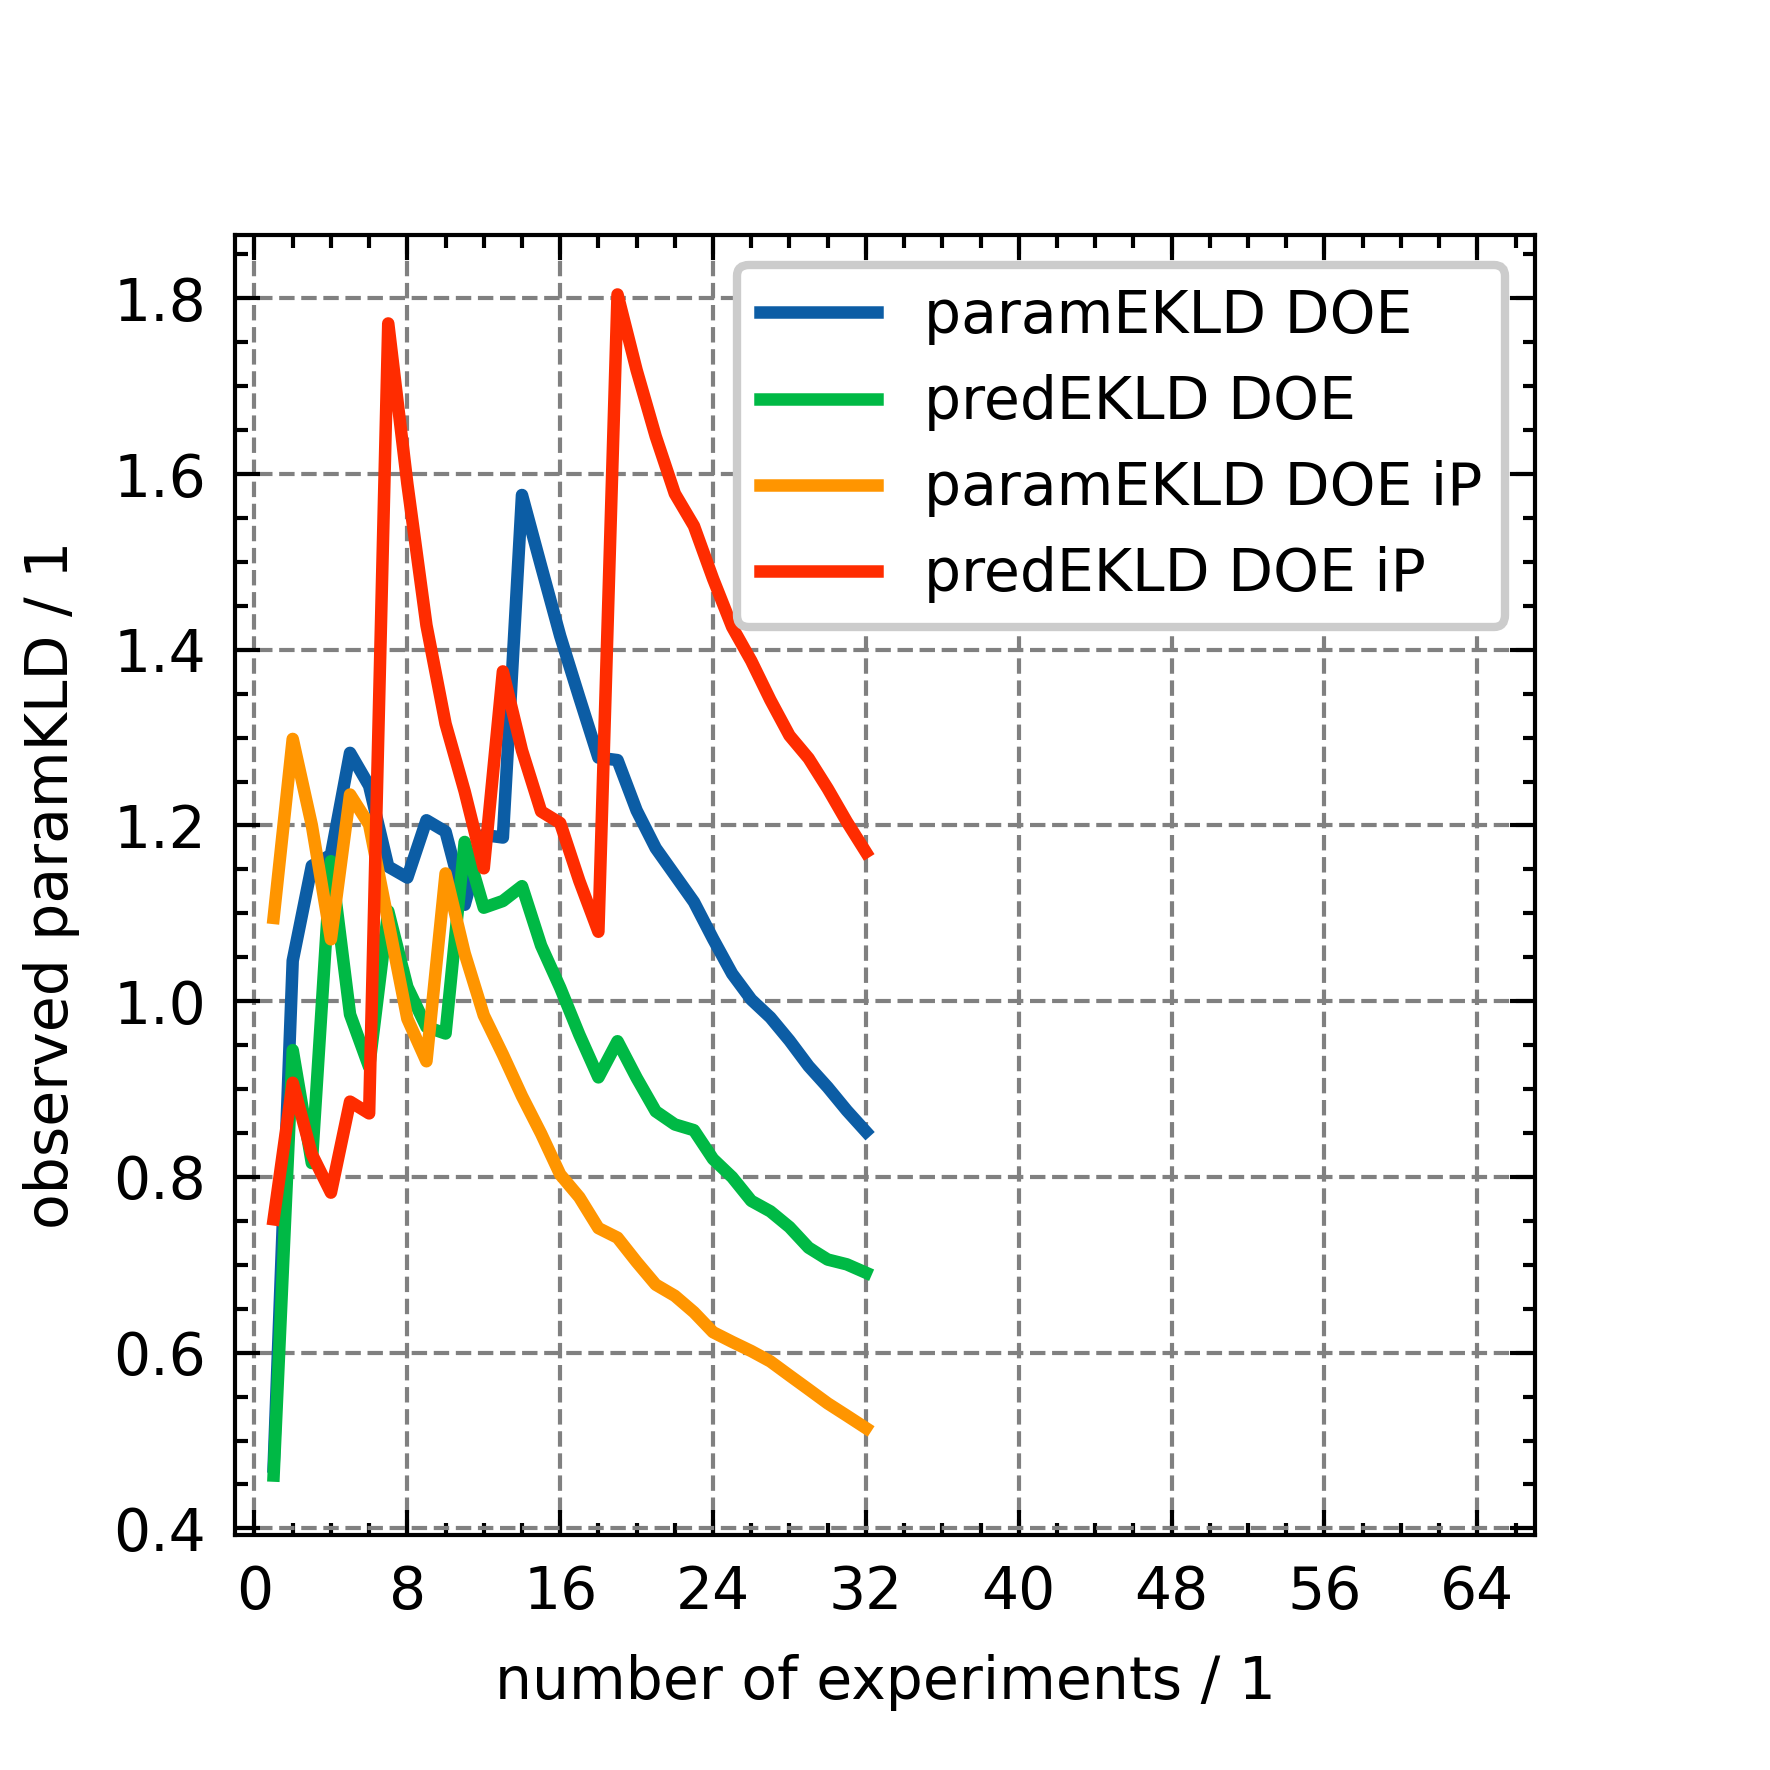

In [20]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel="observed paramKLD / 1",
    # ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
)
for i, ov_dict in enumerate(ov):
    ax.plot(
        x := np.arange(len(ov_dict["paramEKLDS"])) + 1,
        np.cumsum(ov_dict["paramEKLDS"]) / x,
        label=ov_dict["DOE"],
    )
    ax.legend()

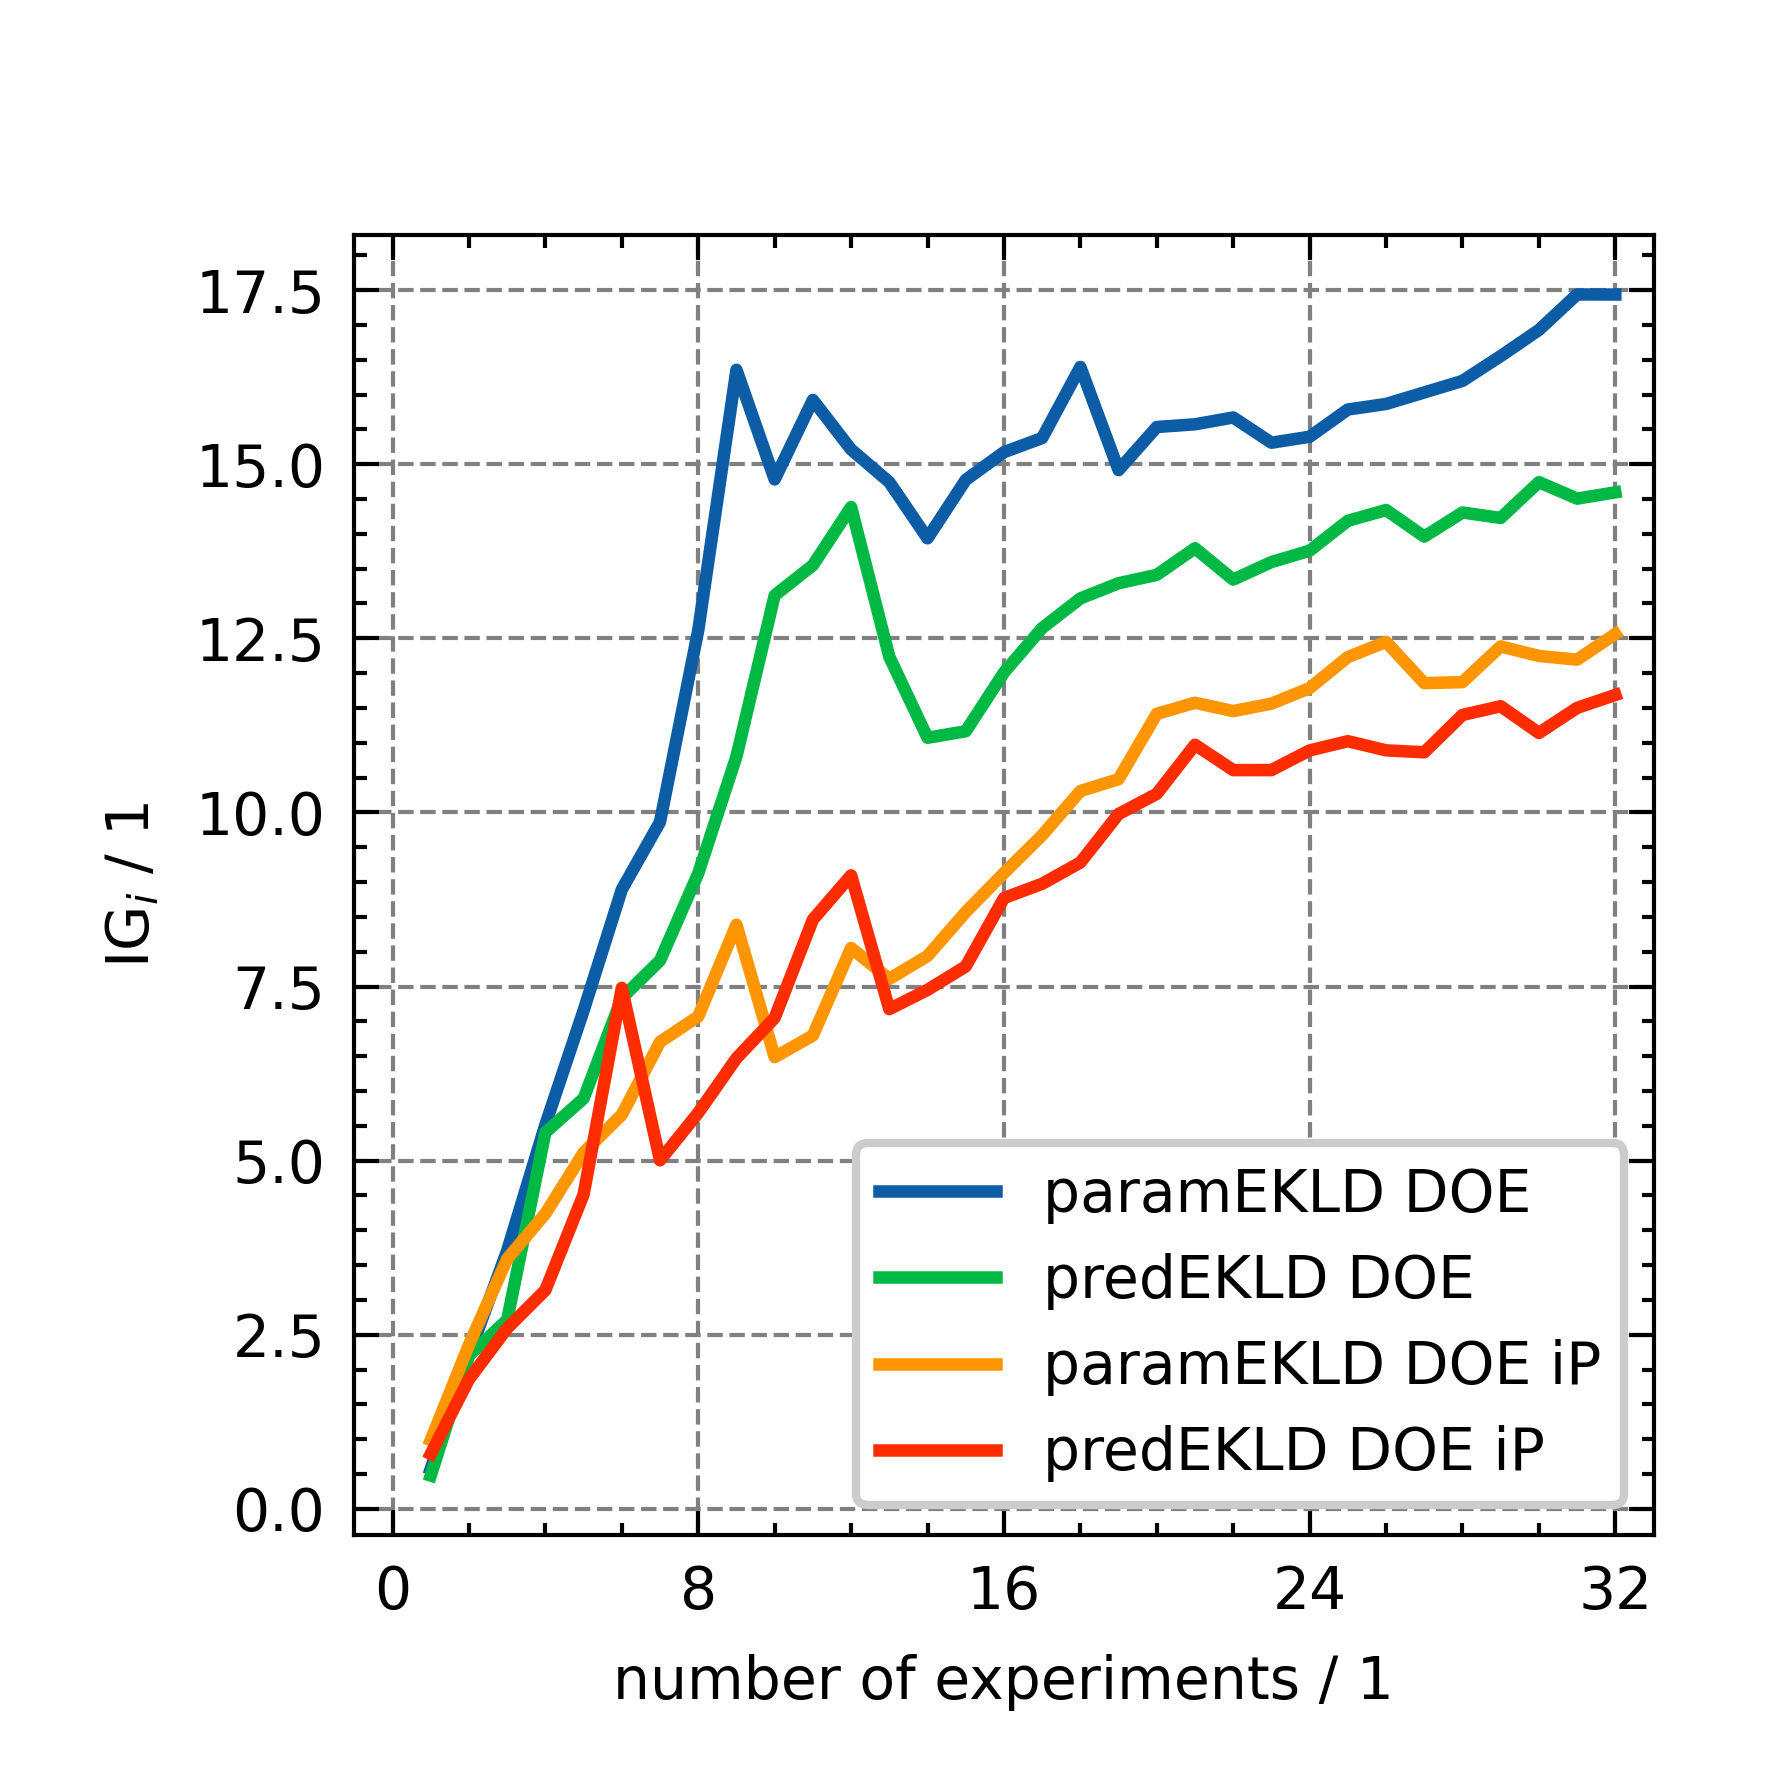

In [32]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"$\mathrm{IG}_i$ / 1",
    # ylim=(6e-7, 1e-4),
    xlim=(-1, 33),
    xticks=[0, 8, 16, 24, 32],
    left_h=1.5 * ICIW_Plots.cm2inch,
)
for i, ov_dict in enumerate(ov):
    ax.plot(
        np.arange(len(ov_dict["paramEKLDS_to_prior"])) + 1,
        ov_dict["paramEKLDS_to_prior"],
        label=ov_dict["DOE"],
    )
    ax.legend()

plt.savefig("figures/KinFit_IG_iP.png")
plt.savefig("figures/KinFit_IG_iP.pdf")
plt.savefig("figures/KinFit_IG_iP.svg")

### Posterior Predictive

In [22]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])
    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range for evaluation
    T = jnp.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range
    T = jnp.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(
        T, p, c2h, c2m, c2w, c2i, rel_noise_std=0.0
    )

    return true_rates


def plot_predictions(fig, ax, posterior_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    ax.legend(loc="upper left")
    return fig, ax

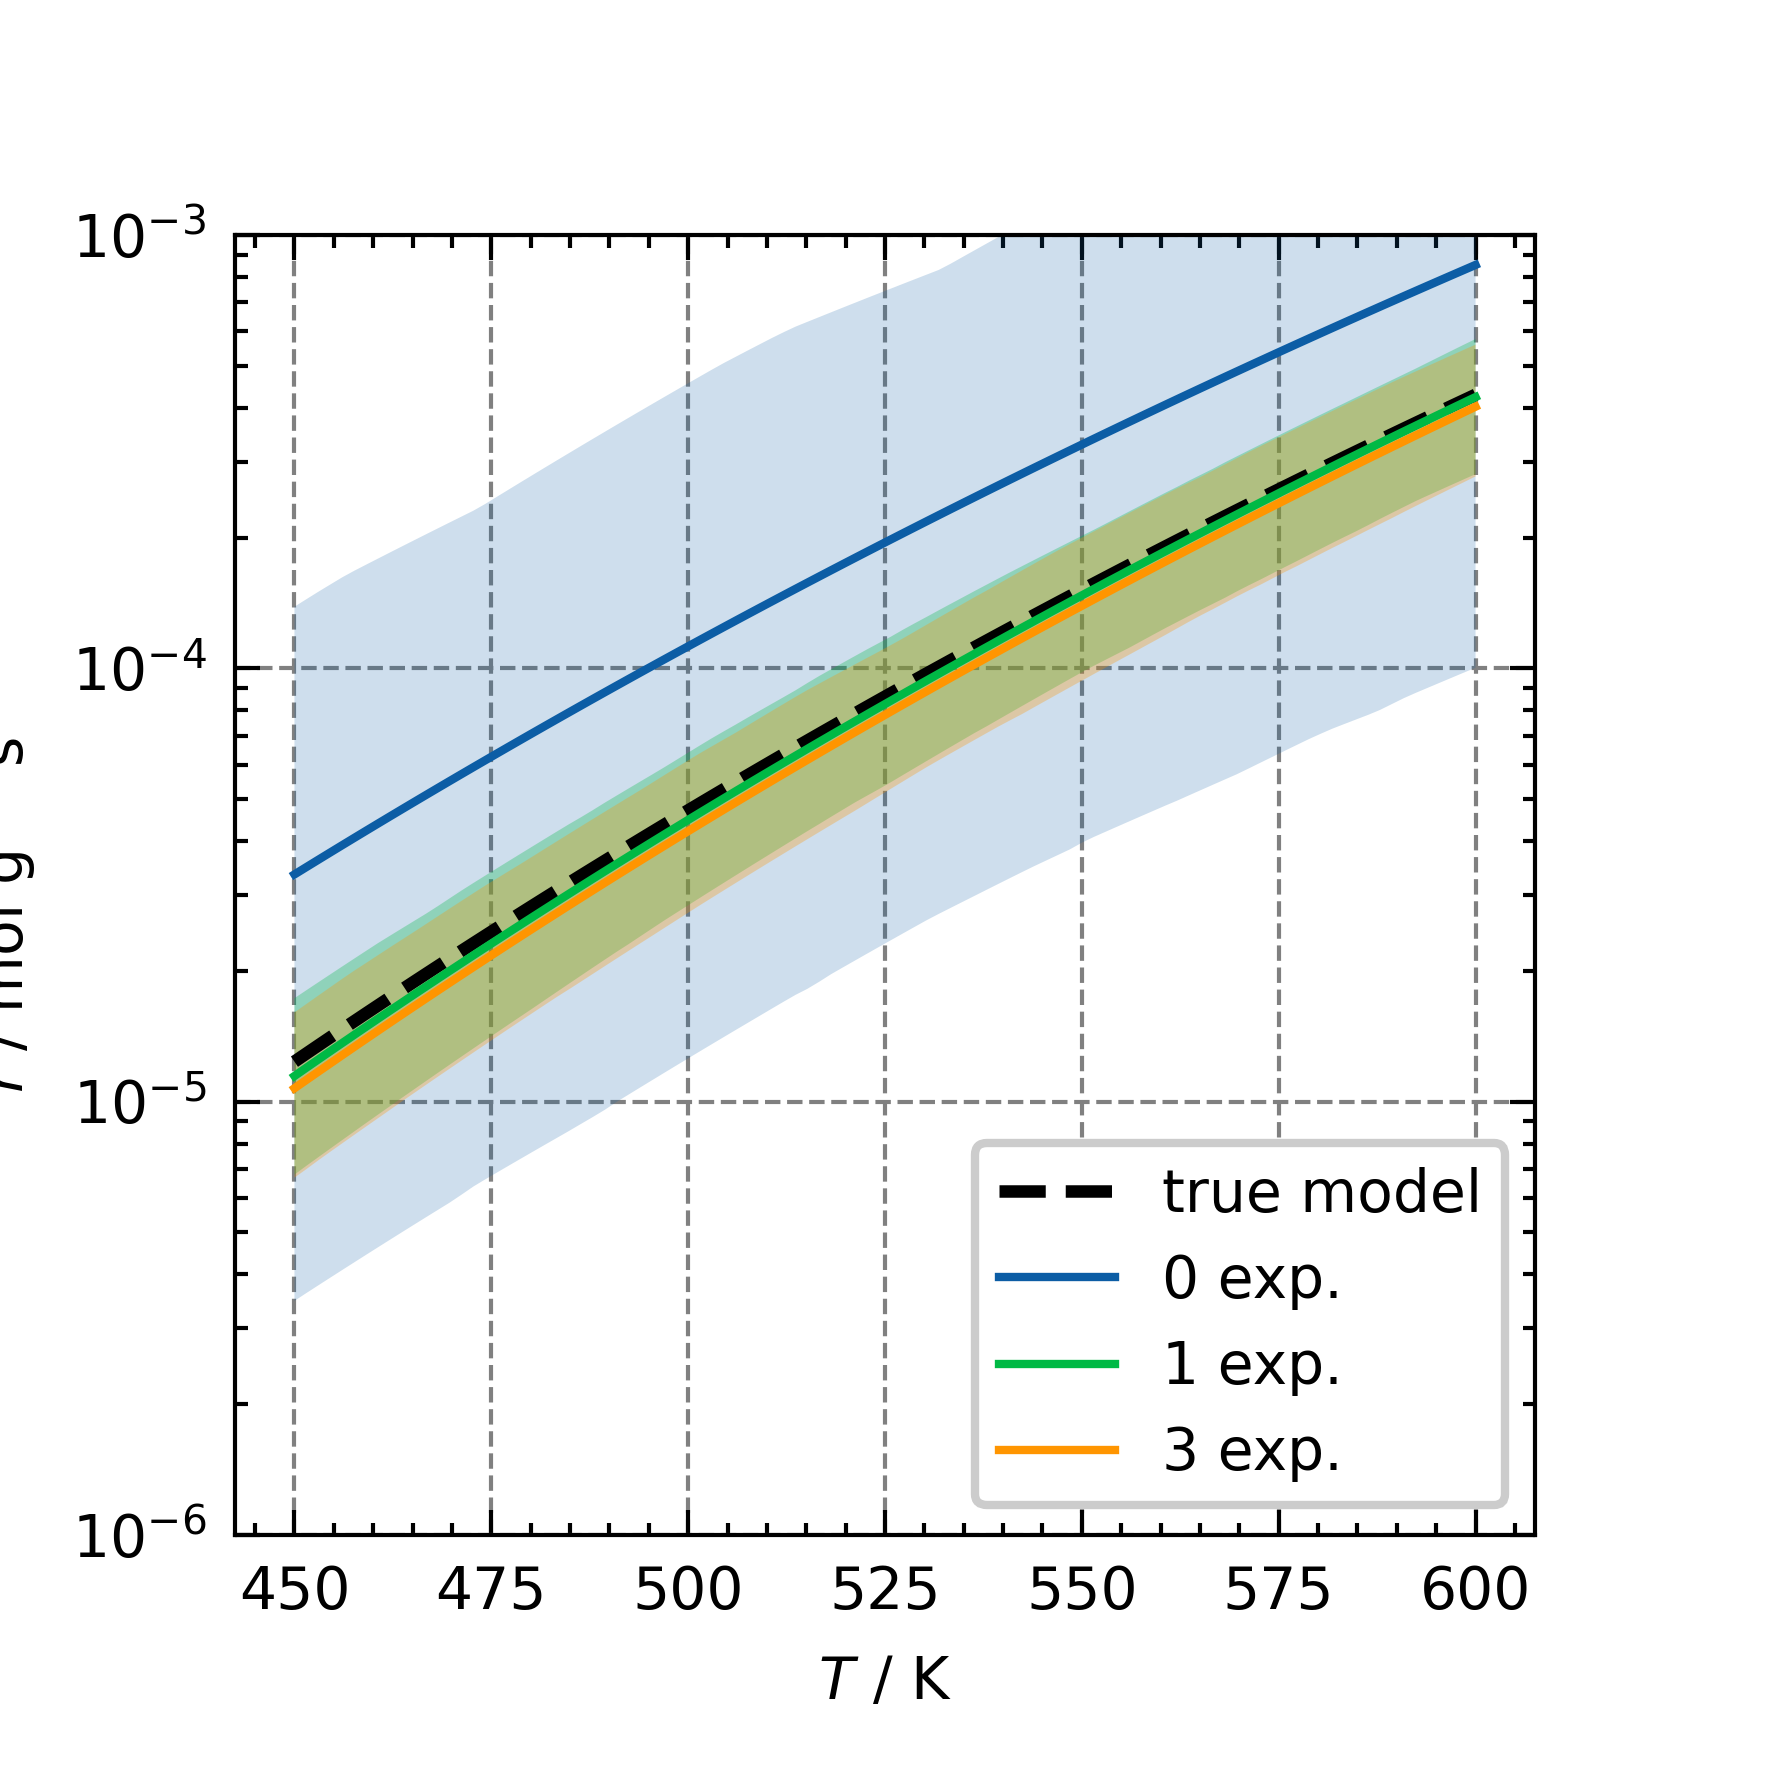

In [23]:
j = 4
T_range = np.linspace(450, 600, 100)
fig = ICIW_Plots.figure(layout="single_column")
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="$T$ / K",
    ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
    yscale="log",
    ylim=(1e-6, 1e-3),
    # xlim=(450, 600),
)
true_res = evaluate_true_model(
    proposal=ov[-1]["proposals"][j],
)
ax.plot(
    T_range,
    true_res.squeeze(),
    label="true model",
    color="black",
    linestyle="--",
    # linewidth=2,
)
# i=0
test_res = evaluate_conditions(
    proposal=ov[-1]["proposals"][j],
    idata=ov[-1]["idatas"][0],
    key="prior",
)
ax.plot(
    T_range,
    test_res.mean(axis=1),
    label="0 exp.",
    linewidth=1.0,
)
ax.fill_between(
    T_range,
    np.percentile(test_res, 2.5, axis=1),
    np.percentile(test_res, 97.5, axis=1),
    alpha=0.2,
)
# i=1
test_res = evaluate_conditions(
    proposal=ov[-1]["proposals"][j],
    idata=ov[-1]["idatas"][1],
    key="posterior",
)
ax.plot(
    T_range,
    test_res.mean(axis=1),
    label="1 exp.",
    linewidth=1.0,
)
ax.fill_between(
    T_range,
    np.percentile(test_res, 2.5, axis=1),
    np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
)
# i=3
test_res = evaluate_conditions(
    proposal=ov[-1]["proposals"][j],
    idata=ov[-1]["idatas"][3],
    key="posterior",
)
ax.plot(
    T_range,
    test_res.mean(axis=1),
    label="3 exp.",
    linewidth=1.0,
    # color="firebrick",
)
ax.fill_between(
    T_range,
    np.percentile(test_res, 2.5, axis=1),
    np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    # facecolor="firebrick",
)
plt.legend(loc="lower right", frameon=True)
# plt.savefig("B_035_Predictions.png", dpi=600, bbox_inches="tight")
# plt.savefig("B_035_Predictions.svg")

### Parameter identified

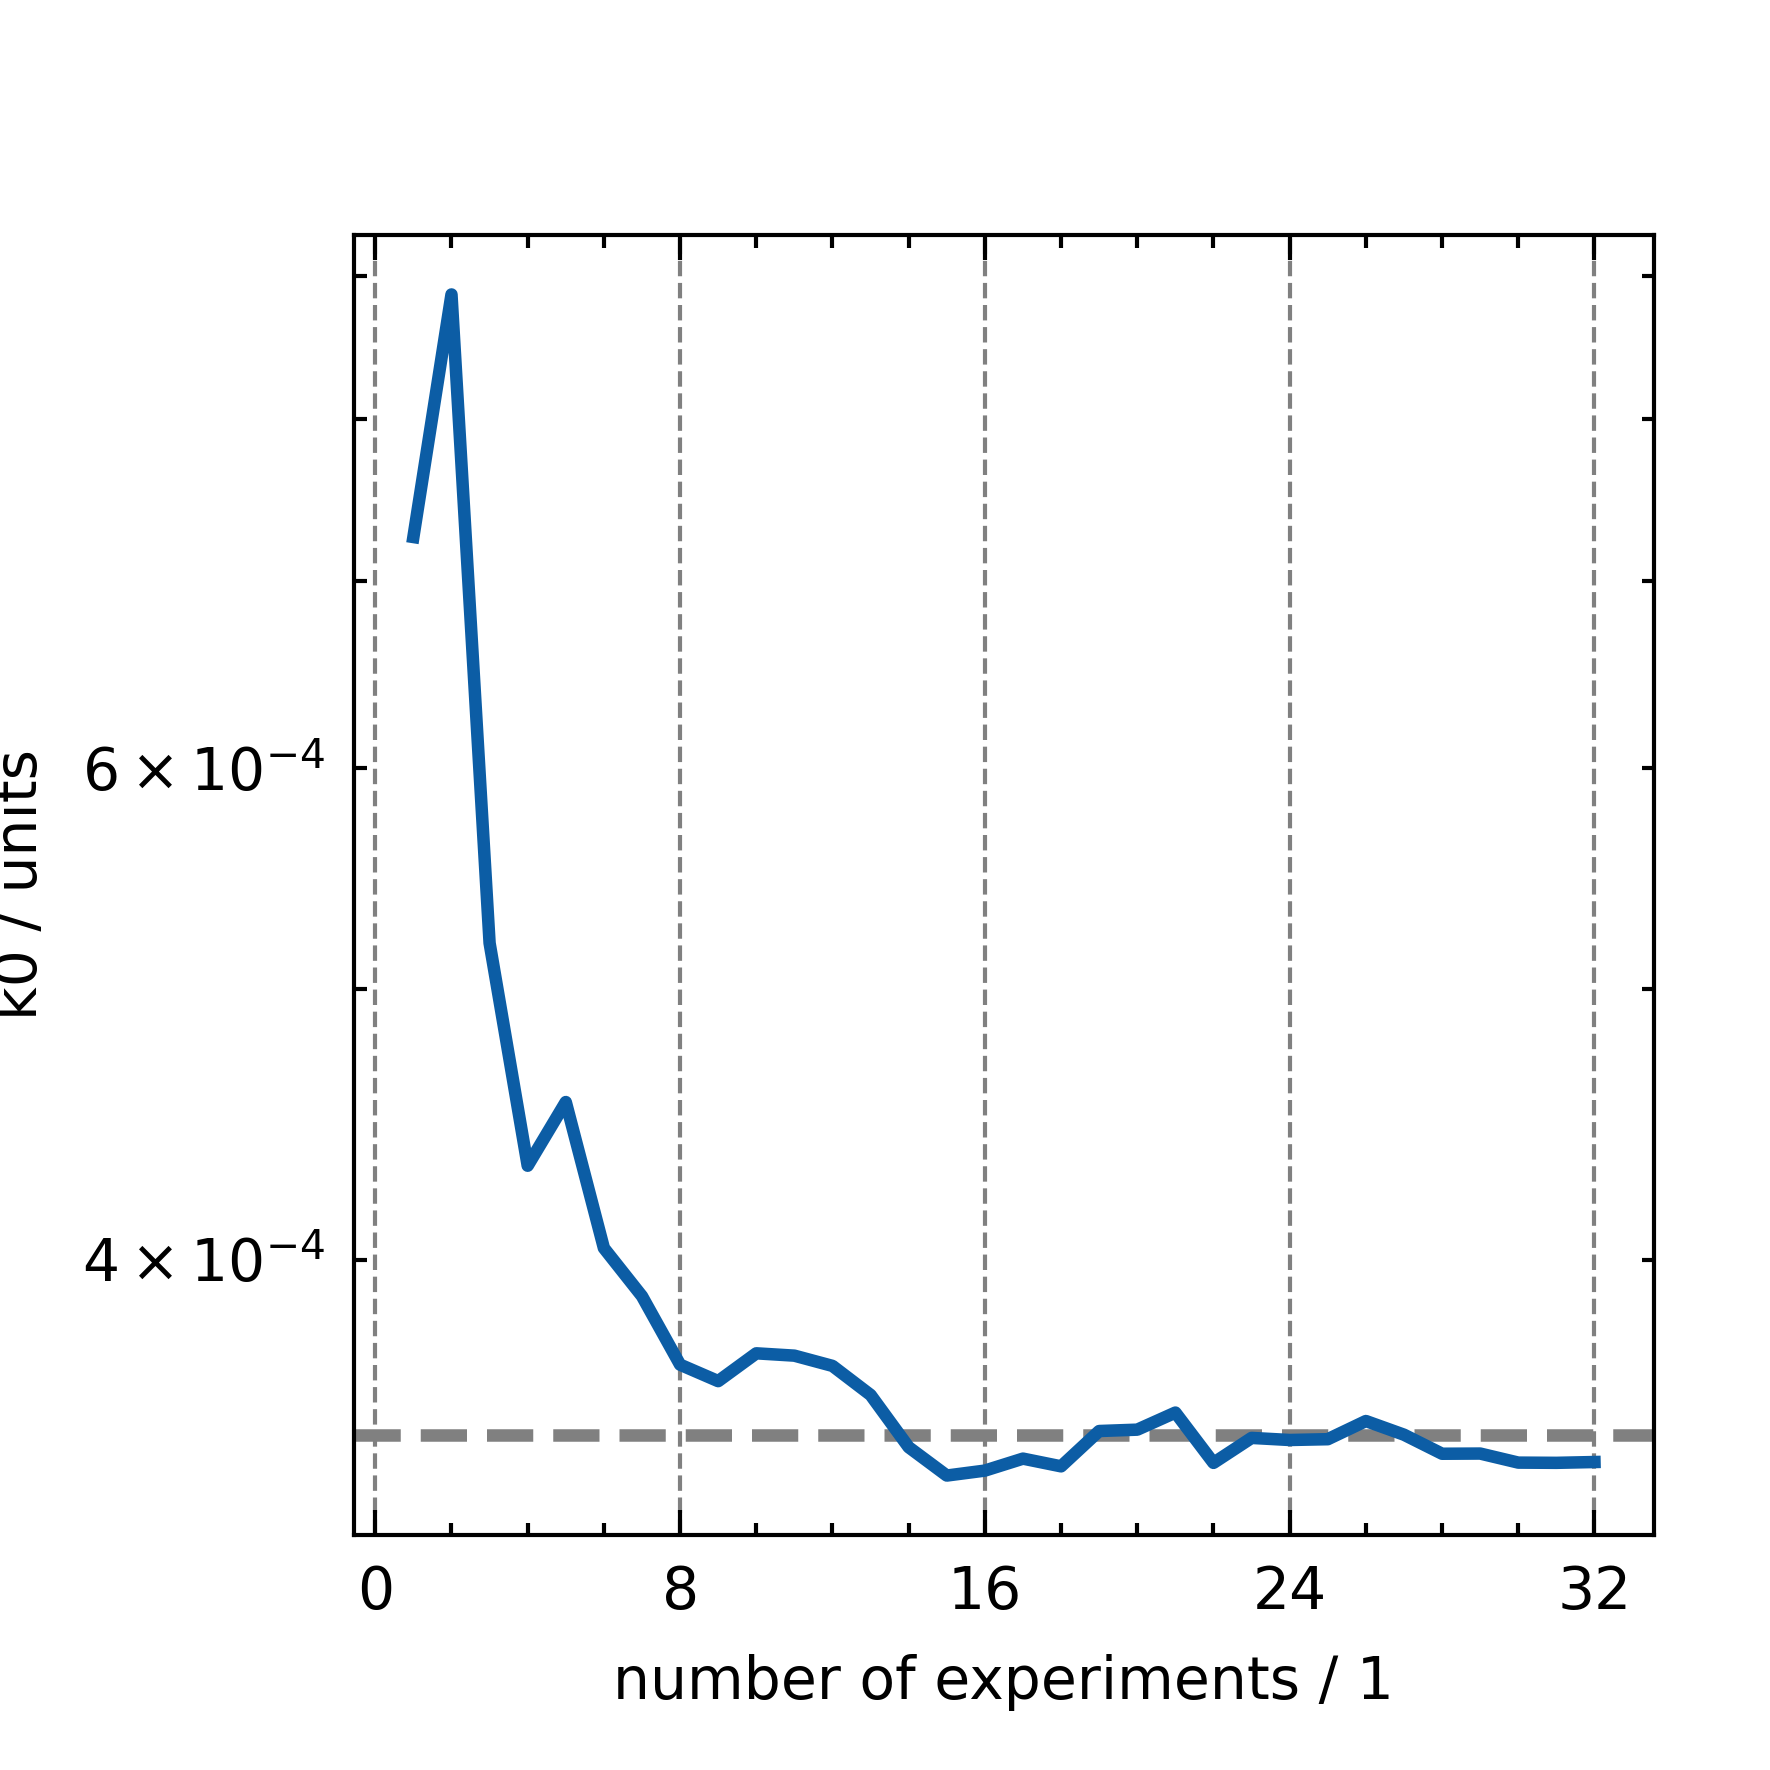

interactive(children=(Dropdown(description='Parameter:', options=('k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h…

In [24]:
from ipywidgets import interact, Dropdown

keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}


@interact(
    key=Dropdown(
        options=keydict.keys(),
        value="k0",
        description="Parameter:",
    ),
)
def plot_parameter_evolution(key):
    fig = ICIW_Plots.figure()
    ax = ICIW_Plots.make_square_ax(
        fig,
        ax_width=5.5 * ICIW_Plots.cm2inch,
        xlabel="number of experiments / 1",
        ylabel=f"{keydict[key]} / units",
        yscale="log",
        # ylim=(6e-7, 1e-4),
        # xlim=(-1, 67),
        xticks=[0, 8, 16, 24, 32, 40, 48, 56, 64],
        left_h=1.5 * ICIW_Plots.cm2inch,
    )
    # ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    for i, ov_dict in enumerate(ov):
        param_samples = []
        for idata in ov_dict["idatas"]:
            samples = idata.posterior[key].values.flatten()
            param_samples.append(samples)
        param_samples = np.array(param_samples)
        ax.axhline(
            y=TRUE_PARAMS[keydict[key]],
            color="gray",
            linestyle="dashed",
            zorder=0,
        )
        if ov_dict["DOE"] == "Koschany DOE":
            ax.hlines(
                np.mean(param_samples, axis=1)[-1],
                xmin=-1,
                xmax=64,
                label=ov_dict["DOE"],
                ls="--",
                color=colors[i],
            )
            HDI = az.hdi(param_samples[-1], hdi_prob=0.95)
            ax.fill_between(
                np.arange(-1, len(param_samples) + 1),
                HDI[0],
                HDI[1],
                alpha=0.2,
                # ls="--",
                facecolor=colors[i],
                # edgecolor="gray",
            )
            continue
        ax.plot(
            np.arange(1, len(param_samples) + 1),
            np.mean(param_samples, axis=1),
            label=ov_dict["DOE"],
            color=plt.rcParams["axes.prop_cycle"].by_key()["color"][i],
        )
        HDI = az.hdi(param_samples.T, hdi_prob=0.95)
        ax.fill_between(
            np.arange(1, len(param_samples) + 1),
            HDI[:, 0],
            HDI[:, 1],
            alpha=0.2,
            facecolor=plt.rcParams["axes.prop_cycle"].by_key()["color"][i],
        )
        ax.legend(frameon=True)

TypeError: hdi got an unexpected keyword argument: 'hdi_prob'

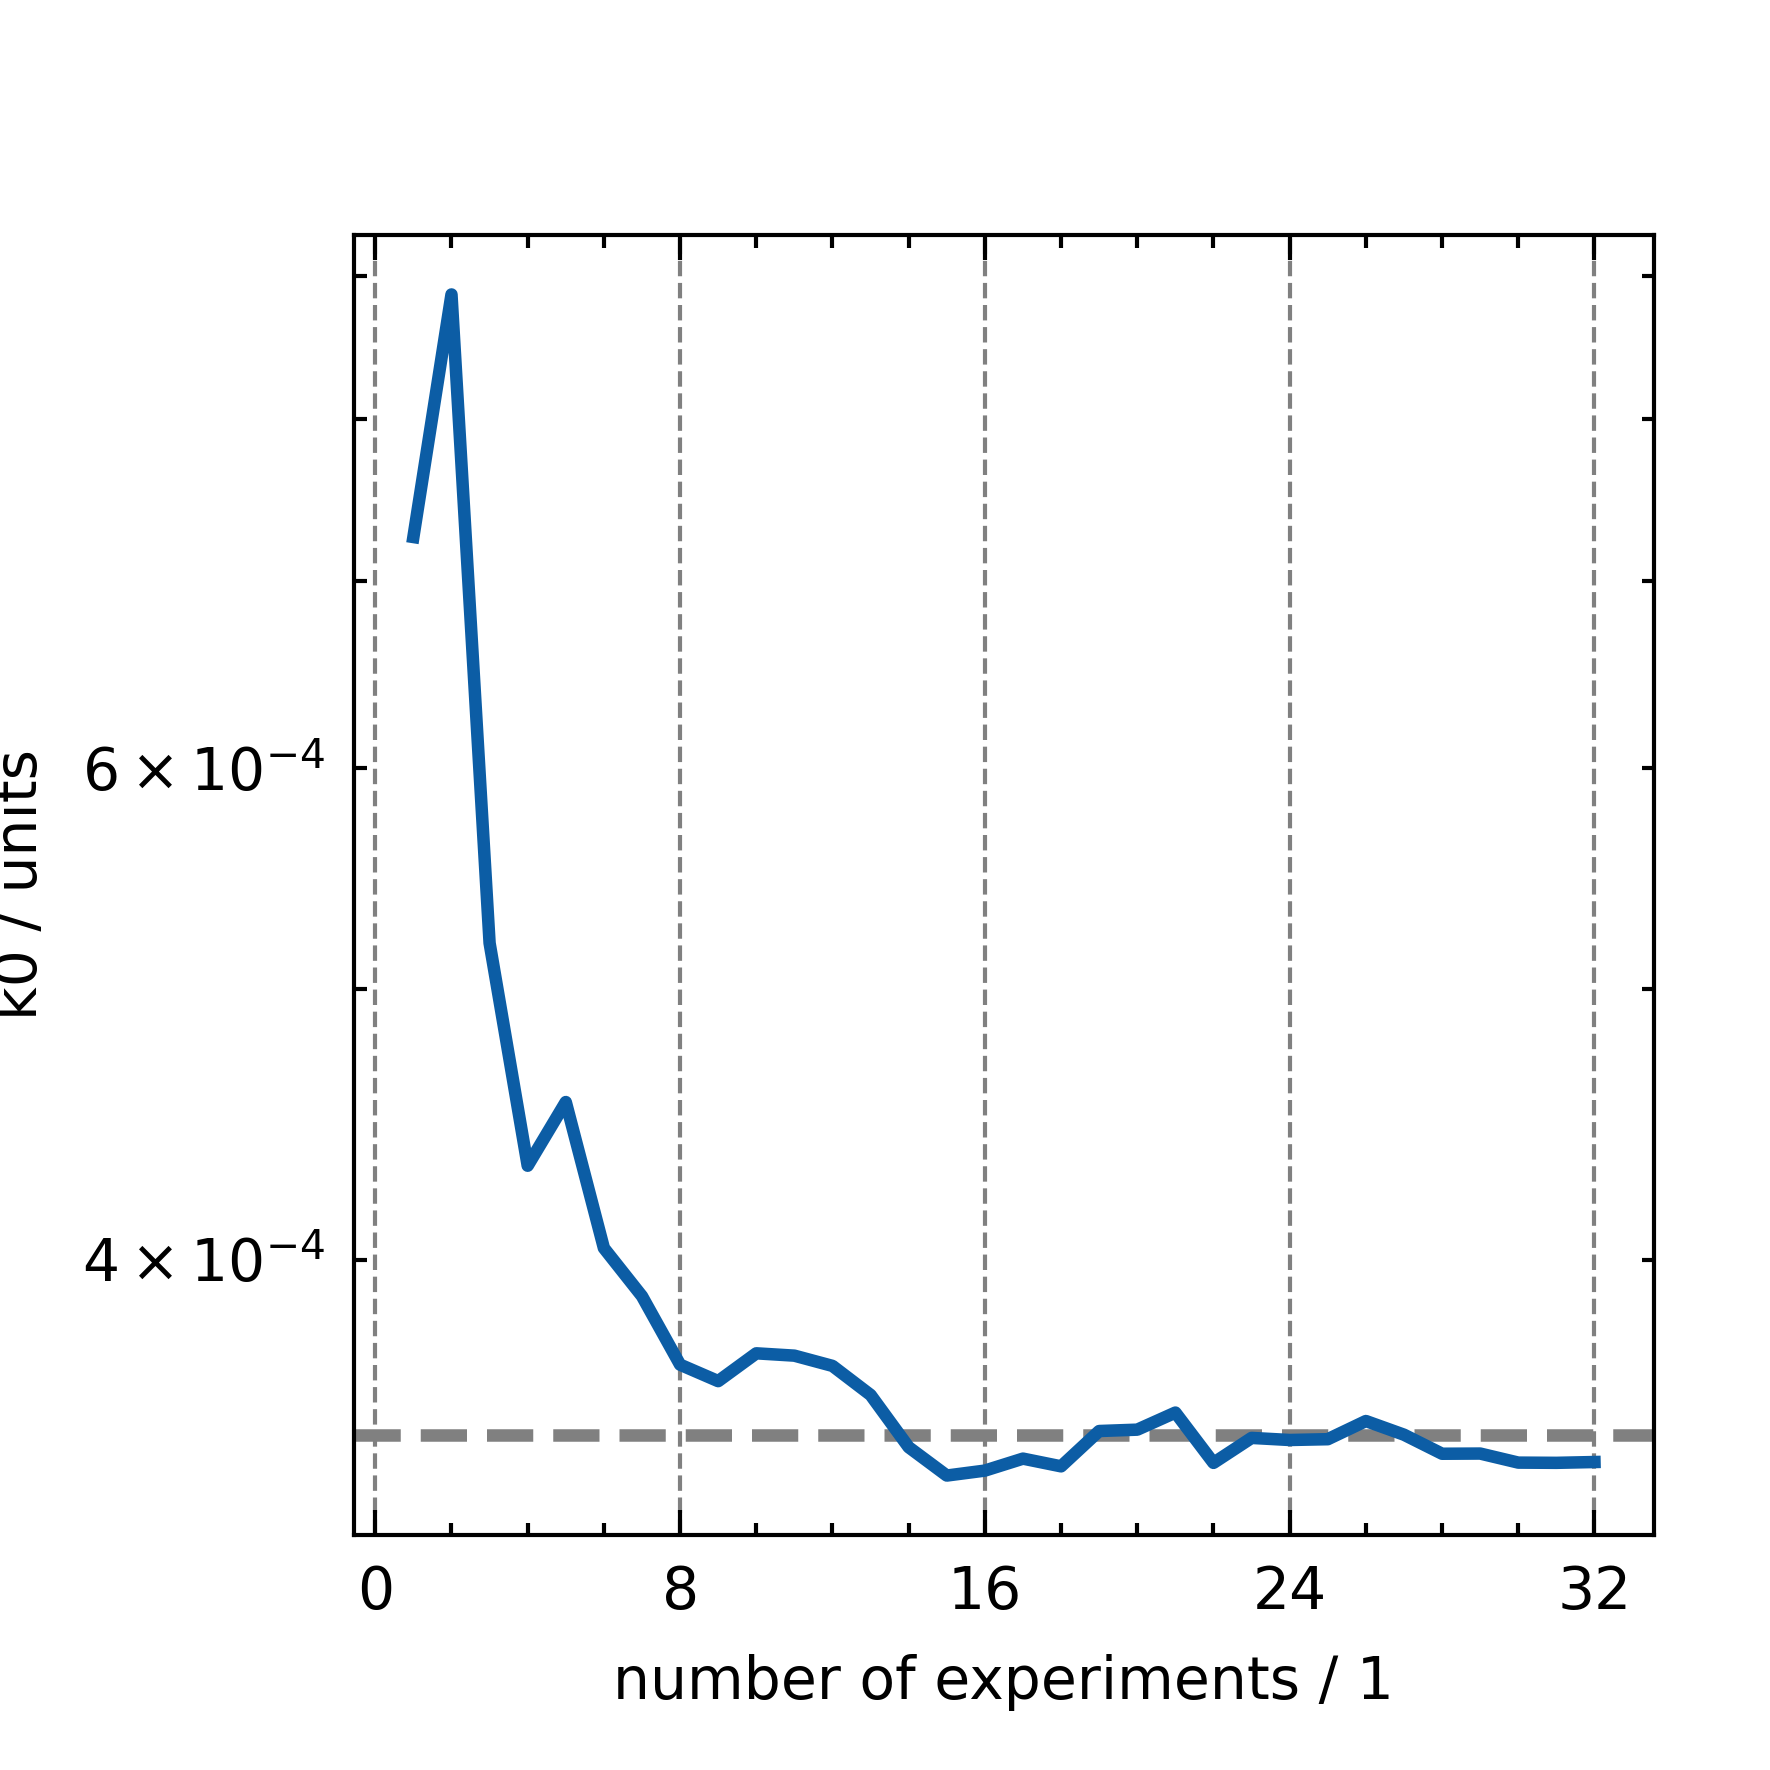

In [25]:
plot_parameter_evolution("k0")
ax = plt.gca()
ax.set_ylabel(r"$A_0^\mathrm{ref}\;/\; \mathrm{s}^{-1}$")
ax.set_ylim(9e-5, 1.5e-3)
plt.savefig("figures/KinFit_k0_evolution.png")
plt.savefig("figures/KinFit_k0_evolution.pdf")
plt.savefig("figures/KinFit_k0_evolution.svg")

In [ ]:
import pandas as pd

# Calculate and print HDI for all parameters across all three DOEs

pd.set_option("display.float_format", lambda x: "%.3e" % x)

param_names = ["k0", "Ea_k", "A_oh", "dH_oh", "A_h2", "dH_h2", "A_mix", "dH_mix"]

results = []

for param in param_names:
    for ov_dict in ov:
        # Get final posterior samples for this parameter
        samples = ov_dict["idatas"][-1].posterior[param].values.flatten()

        # Calculate HDI
        hdi = az.hdi(samples, hdi_prob=0.95)
        mean_val = np.mean(samples)

        results.append(
            {
                "Parameter": param,
                "DOE": ov_dict["DOE"],
                "Mean": mean_val,
                "HDI_lower": hdi[0],
                "HDI_upper": hdi[1],
                "True_value": TRUE_PARAMS[keydict[param]],
            }
        )

# Create DataFrame and display
df_results = pd.DataFrame(results)

# Print results grouped by parameter
for param in ["k0"]:
    print("=" * 80)
    print(f"Parameter: {param}")
    print("-" * 80)
    param_df = df_results[df_results["Parameter"] == param]
    print(
        param_df[["DOE", "Mean", "HDI_lower", "HDI_upper", "True_value"]].to_string(
            index=False
        )
    )
    print()

Parameter: k0
--------------------------------------------------------------------------------
          DOE      Mean  HDI_lower  HDI_upper True_value
 Koschany DOE 3.199e-04  2.351e-04  4.159e-04   0.000346
paramEKLD DOE 3.385e-04  2.960e-04  3.826e-04   0.000346
 predEKLD DOE 3.320e-04  2.902e-04  3.758e-04   0.000346



### Prior

In [ ]:
display(ov[2]["idatas"][0])

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:  (chain: 8, draw: 4000, data: 1)
│       Coordinates:
│         * chain    (chain) int64 64B 0 1 2 3 4 5 6 7
│         * draw     (draw) int64 32kB 0 1 2 3 4 5 6 ... 3994 3995 3996 3997 3998 3999
│         * data     (data) int64 8B 0
│       Data variables:
│           A_h2     (chain, draw) float32 128kB ...
│           A_mix    (chain, draw) float32 128kB ...
│           A_oh     (chain, draw) float32 128kB ...
│           Ea_k     (chain, draw) float32 128kB ...
│           dH_h2    (chain, draw) float32 128kB ...
│           dH_mix   (chain, draw) float32 128kB ...
│           dH_oh    (chain, draw) float32 128kB ...
│           k0       (chain, draw) float32 128kB ...
│           r_pred   (chain, draw, data) float32 128kB ...
│           sigma_r  (chain, draw) float32 128kB ...
│       Attributes:
│           created_at:                 2025-11-25T12:52:57.611411+00:00
│           arviz_version:              0.22.0
│           inference_library:          numpyro
│           inference_library_version:  0.19.0
├── Group: /log_likelihood
│       Dimensions:  (chain: 8, draw: 4000, data: 1)
│       Coordinates:
│         * chain    (chain) int64 64B 0 1 2 3 4 5 6 7
│         * draw     (draw) int64 32kB 0 1 2 3 4 5 6 ... 3994 3995 3996 3997 3998 3999
│         * data     (data) int64 8B 0
│       Data variables:
│           r        (chain, draw, data) float32 128kB ...
│       Attributes:
│           created_at:                 2025-11-25T12:52:57.774033+00:00
│           arviz_version:              0.22.0
│           inference_library:          numpyro
│           inference_library_version:  0.19.0
├── Group: /sample_stats
│       Dimensions:    (chain: 8, draw: 4000)
│       Coordinates:
│         * chain      (chain) int64 64B 0 1 2 3 4 5 6 7
│         * draw       (draw) int64 32kB 0 1 2 3 4 5 6 ... 3994 3995 3996 3997 3998 3999
│       Data variables:
│           diverging  (chain, draw) bool 32kB ...
│       Attributes:
│           created_at:                 2025-11-25T12:52:57.627106+00:00
│           arviz_version:              0.22.0
│           inference_library:          numpyro
│           inference_library_version:  0.19.0
├── Group: /observed_data
│       Dimensions:  (data: 1)
│       Coordinates:
│         * data     (data) int64 8B 0
│       Data variables:
│           r        (data) float32 4B ...
│       Attributes:
│           created_at:                 2025-11-25T12:52:57.775632+00:00
│           arviz_version:              0.22.0
│           inference_library:          numpyro
│           inference_library_version:  0.19.0
└── Group: /prior
        Dimensions:       (chain: 1, draw: 4000, r_dim_0: 1, r_dim_1: 1,
                           r_pred_dim_0: 1, r_pred_dim_1: 1)
        Coordinates:
          * chain         (chain) int64 8B 0
          * draw          (draw) int64 32kB 0 1 2 3 4 5 ... 3995 3996 3997 3998 3999
          * r_dim_0       (r_dim_0) int64 8B 0
          * r_dim_1       (r_dim_1) int64 8B 0
          * r_pred_dim_0  (r_pred_dim_0) int64 8B 0
          * r_pred_dim_1  (r_pred_dim_1) int64 8B 0
        Data variables:
            A_h2          (chain, draw) float32 16kB 0.5472 0.01061 ... 0.2366 1.837
            A_mix         (chain, draw) float32 16kB 0.2598 0.2438 ... 1.568 0.4982
            A_oh          (chain, draw) float32 16kB 0.01072 0.6042 ... 2.817 1.703
            Ea_k          (chain, draw) float32 16kB 5.173e+03 7.455e+04 ... 4.129e+04
            dH_h2         (chain, draw) float32 16kB -1.151e+04 ... -9.686e+03
            dH_mix        (chain, draw) float32 16kB -1.1e+04 -8.455e+03 ... -1.284e+04
            dH_oh         (chain, draw) float32 16kB 1.685e+03 6.654e+03 ... 5.146e+03
            k0            (chain, draw) float32 16kB 0.0001101 9.523e-05 ... 0.001482
            r             (chain, draw, r_dim_0, r_dim_1) float32 16kB 4.675e-05 ... ...
            r_pred        (chain, draw, 

Current ArviZ rcParams:
  data.http_protocol
  data.index_origin
  data.sample_dims
  data.save_warmup
  plot.backend
  plot.density_kind
  plot.max_subplots
  stats.ci_kind
  stats.ci_prob
  stats.envelope_prob
  stats.ic_compare_method
  stats.ic_pointwise
  stats.ic_scale
  stats.module
  stats.point_estimate
  stats.round_to


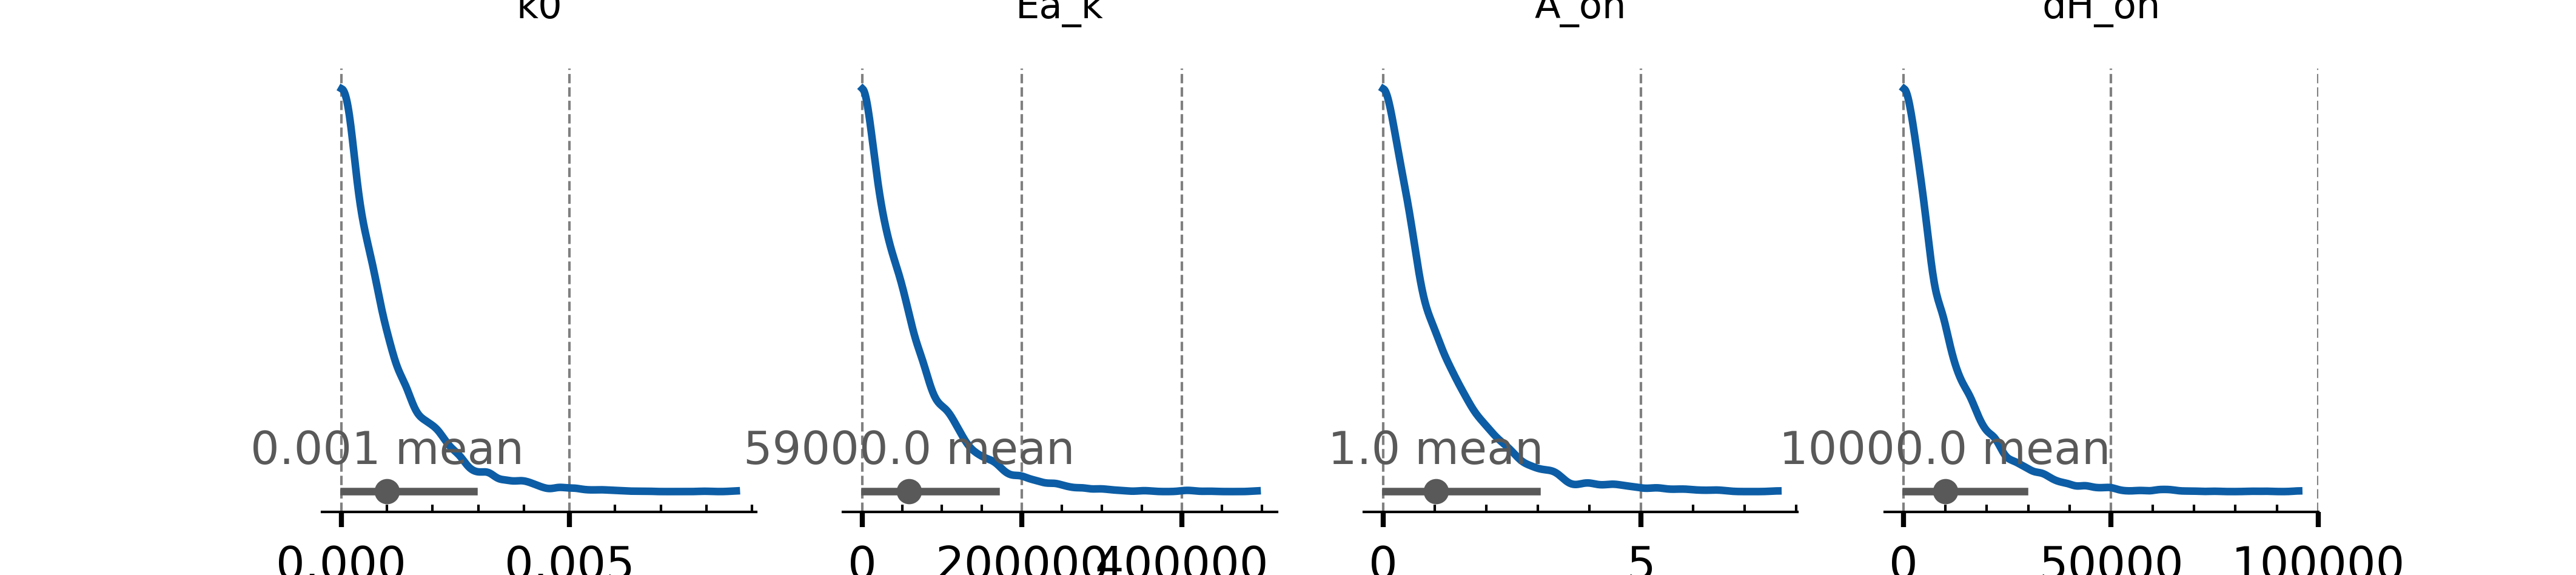

In [ ]:
for key, value in plt.rcParams.items():
    if key in az.rcParams:
        print(f"Setting ArviZ rcParam '{key}' to match Matplotlib rcParam '{key}'.")
        az.rcParams[key] = value

print("Current ArviZ rcParams:")
for key in az.rcParams.keys():
    print(f"  {key}")

plt.style.use("ICIWstyle")
az.plot_dist(
    ov[2]["idatas"][0], group="prior", var_names=["k0", "Ea_k", "A_oh", "dH_oh"]
)

plt.savefig("figures/priors_for talk.svg")

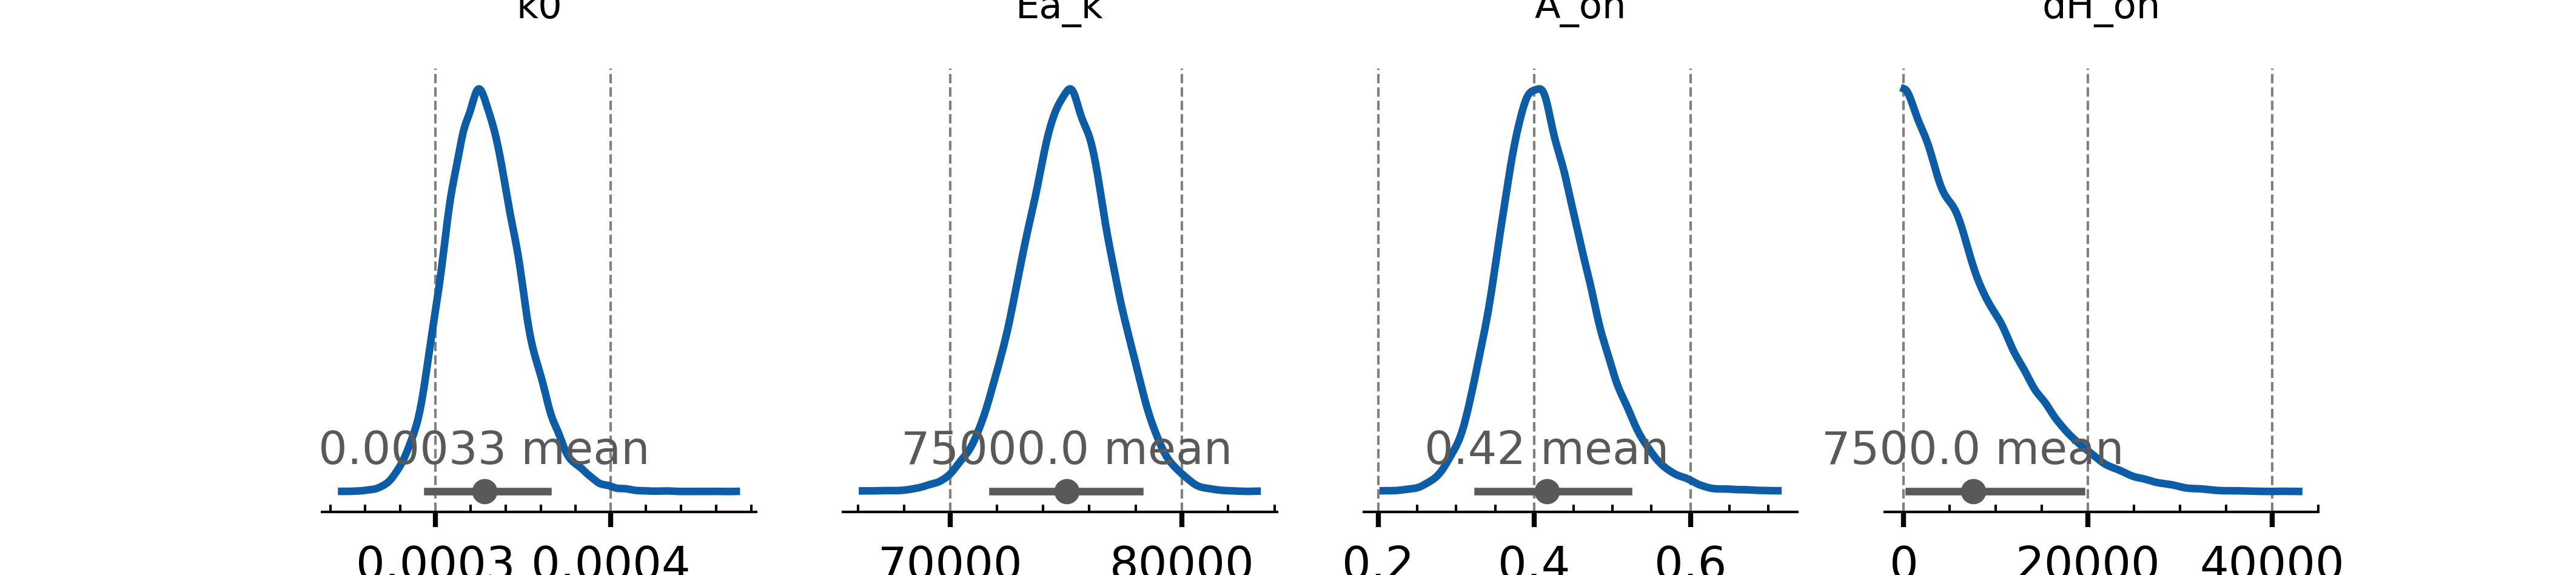

In [ ]:
plt.style.use("ICIWstyle")
az.plot_dist(
    ov[2]["idatas"][-1], group="prior", var_names=["k0", "Ea_k", "A_oh", "dH_oh"]
)
plt.savefig("figures/posterior_for_talk.svg")

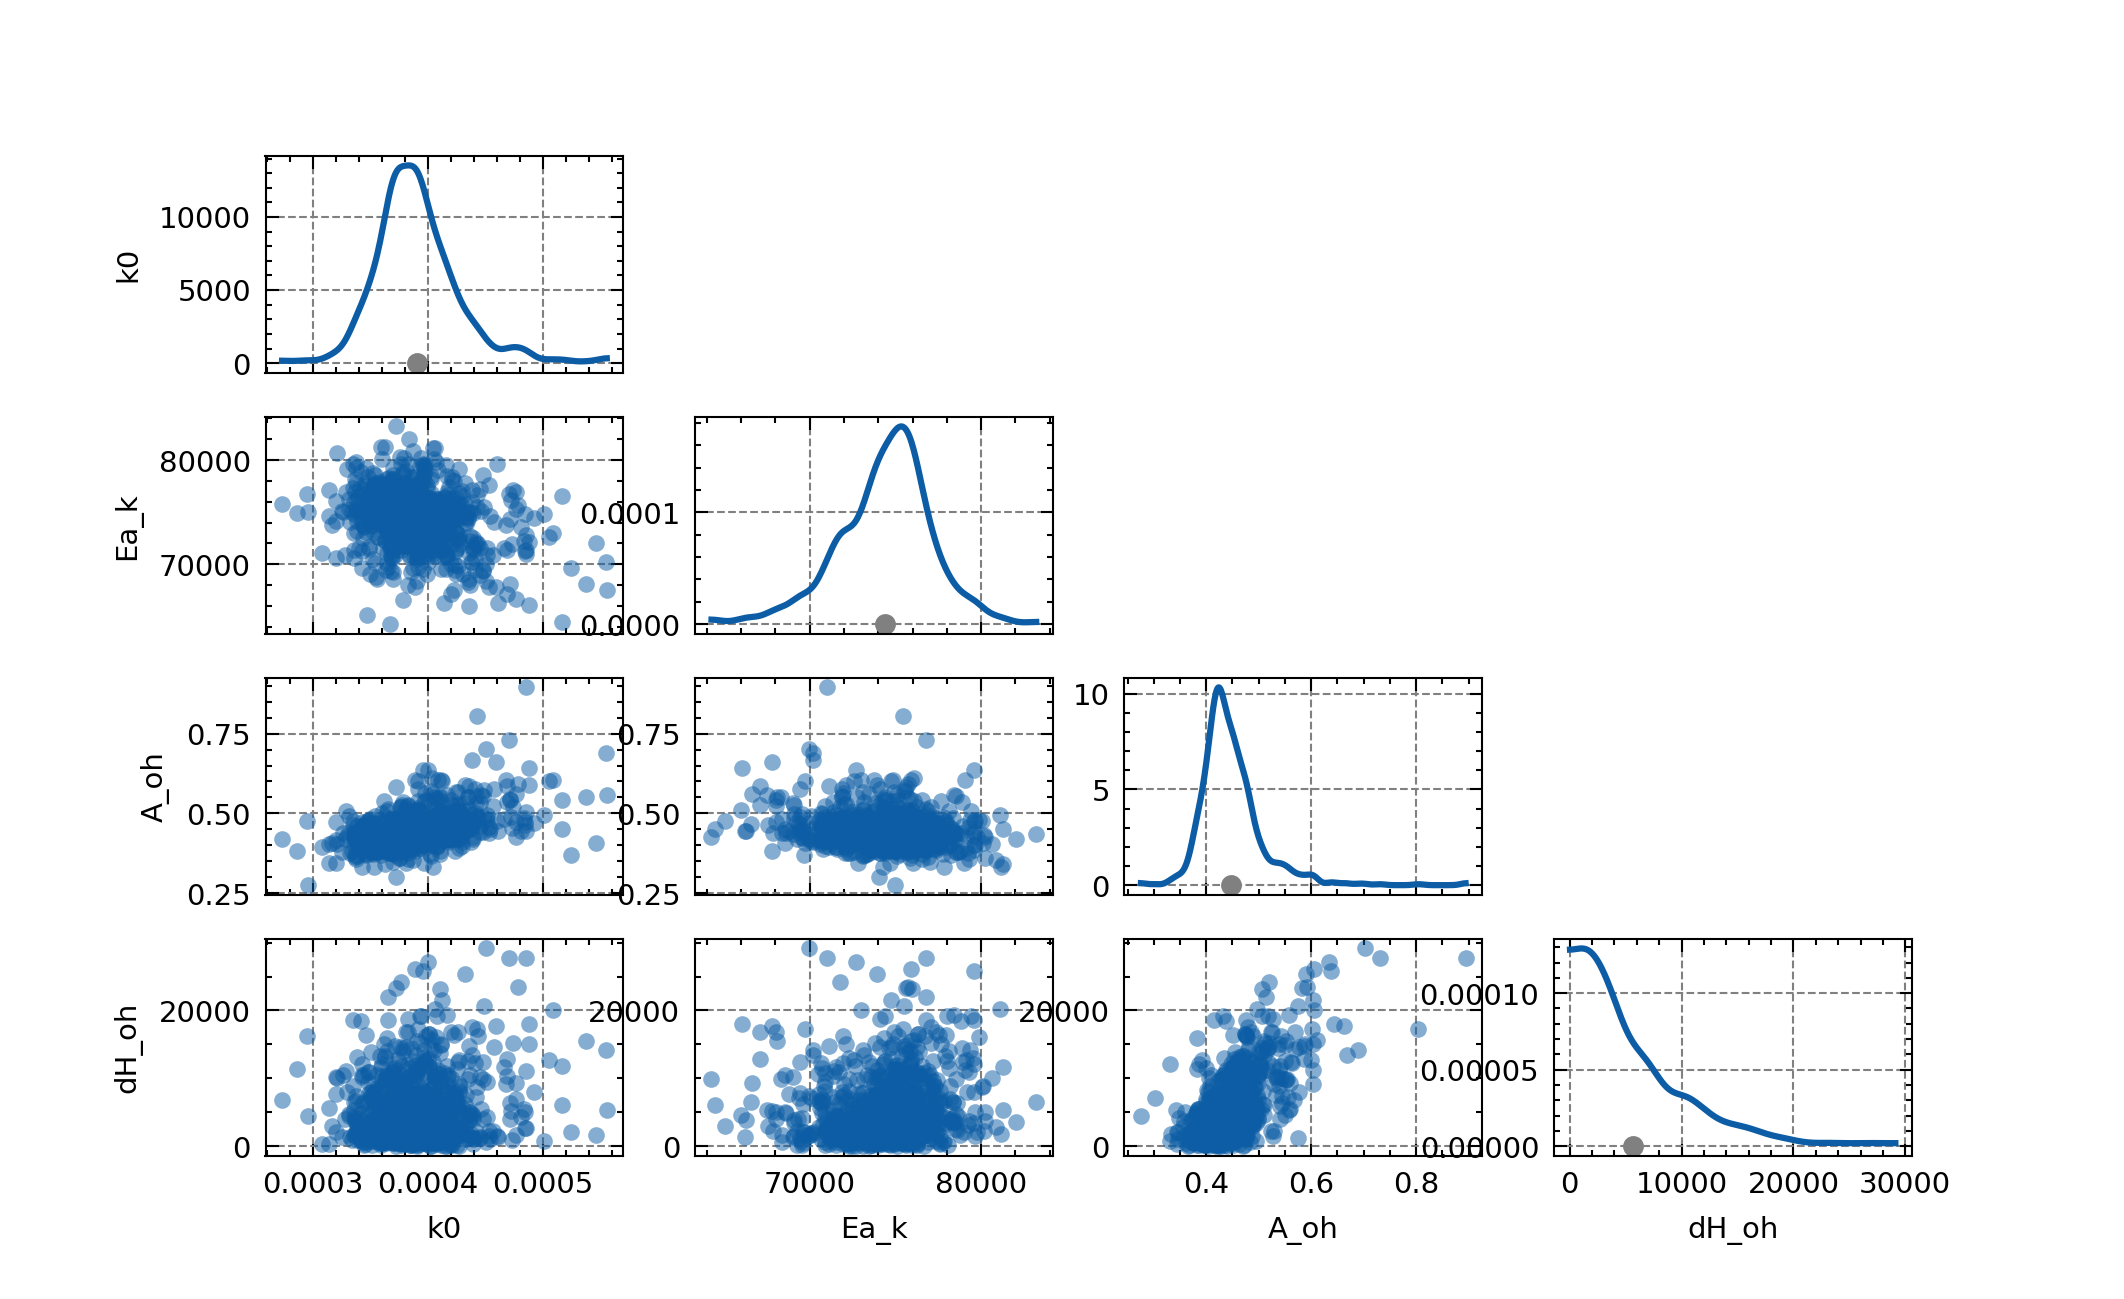

In [ ]:
plt.rcParams.update(
    {
        "font.size": 7,
        "figure.dpi": 300,
    },
)

data = az.extract(ov[2]["idatas"][10], sample_dims="draw", num_samples=100)

az.plot_pair(
    data,
    # group="posterior",
    var_names=["k0", "Ea_k", "A_oh", "dH_oh"],
    visuals={
        "point_estimate": {"color": "grey"},
    },
)
plt.savefig("figures/posterior_pairplot.svg")

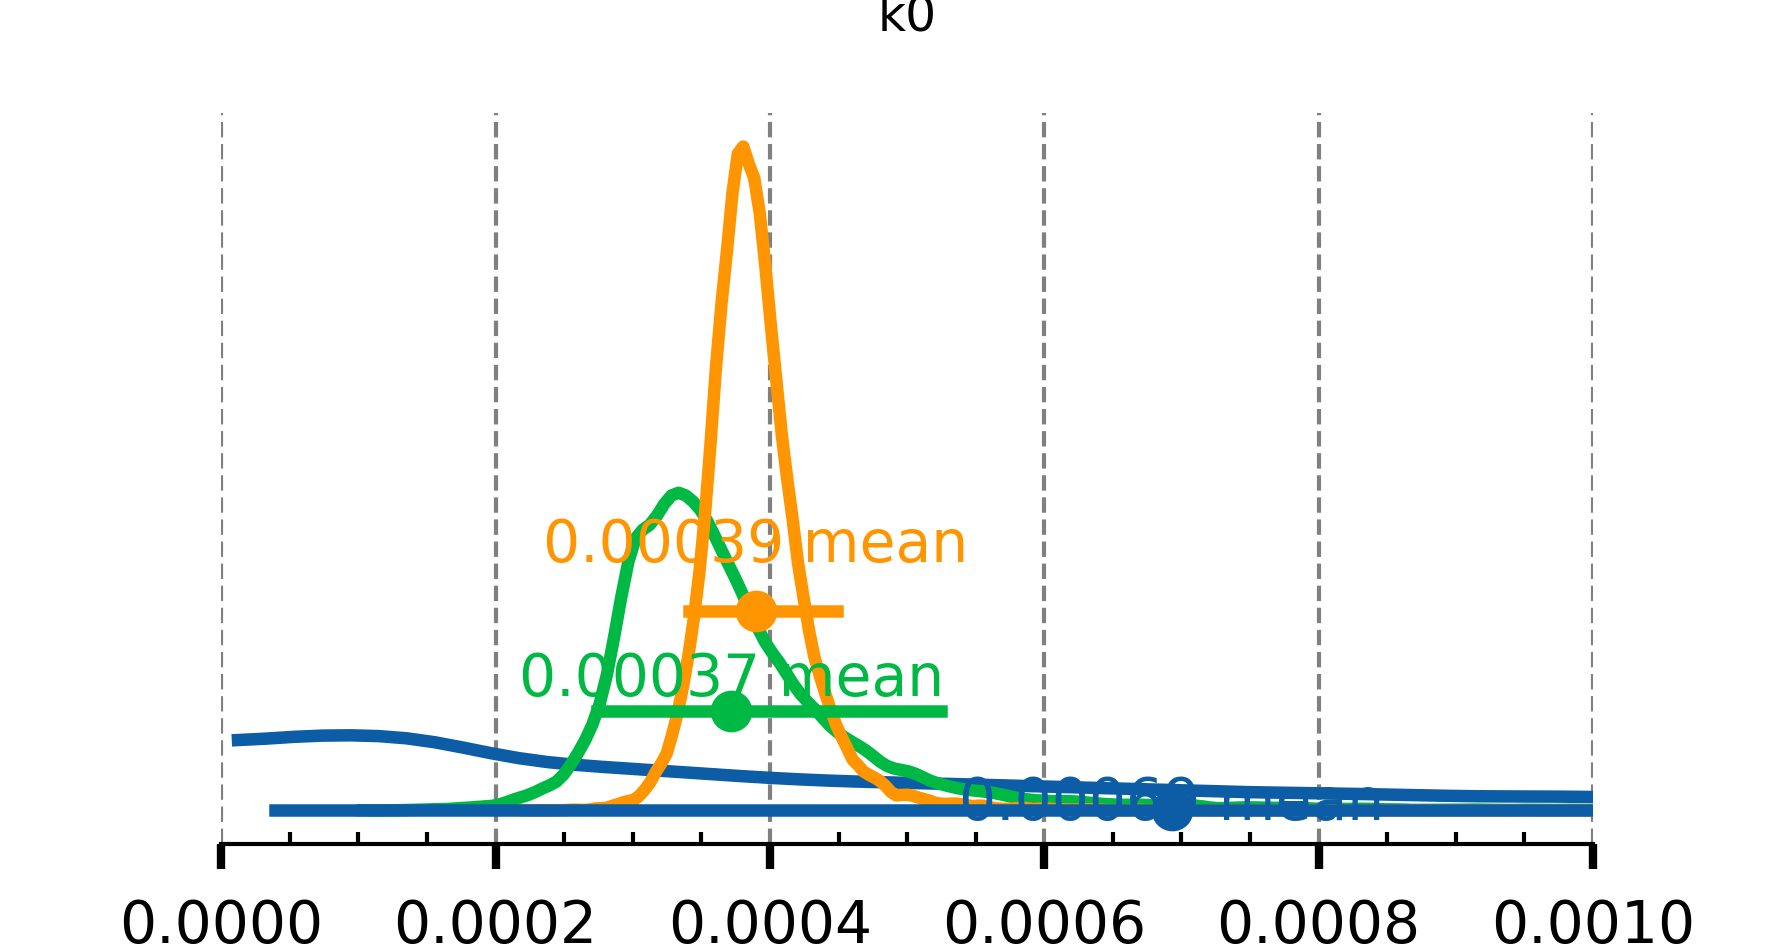

In [ ]:
ax = az.plot_dist(
    {
        "prior": ov[2]["idatas"][0],
        "pre": ov[2]["idatas"][4],
        "post": ov[2]["idatas"][10],
    },
    # group="posterior",
    var_names=[
        "k0",
    ],
)
ax = plt.gca()
plt.xlim(0, 0.001)
plt.savefig("figures/k0_prior_posterior.svg")